# Démographie, services publics, ethnicité, religion, emploi et éducation : une information de plus sur la survie des partis autoritaires ?
*Fedi Jouili*

**Objectif.** Les modèles de Cox de `final_panel.ipynb` expliquent la durée de vie des partis autoritaires par leur origine, leur stratégie de gouvernance, leur idéologie, le niveau démocratique et le conflit armé. Ce notebook teste si trois blocs de variables décrivant les **pays** apportent une information au-delà de ces covariables :
* **Bloc A — démographie et services publics** : structure par âge (part des jeunes, part des 65 ans et plus), espérance de vie, scolarisation, urbanisation, inégalités de revenu, capacité fiscale de l'État et qualité des services publics ;
* **Bloc B — ethnicité et religion** : part de la population exclue du pouvoir pour des raisons ethniques, nombre de groupes ethniques politiquement pertinents, répartition du pouvoir entre groupes sociaux, liberté religieuse et répression des organisations religieuses. La fractionnalisation ethnique et religieuse d'Alesina et al. (2003) sert seulement de point de comparaison ;
* **Bloc C — emploi, éducation et liberté académique** : chômage (total, des jeunes, des diplômés du supérieur), niveau d'éducation de la population (années moyennes d'études, scolarisation dans le supérieur, part de diplômés) et liberté académique. Ce bloc décrit la place des « intellectuels » : leur nombre, leur emploi et la liberté que l'État leur laisse. Une population plus instruite, et en particulier des diplômés sans emploi, figure souvent parmi les menaces pour les régimes autoritaires (Glaeser, Ponzetto & Shleifer 2007 ; Campante & Chor 2012).

Pour chaque bloc, trois modèles sont comparés au modèle de Cox existant (**M0**) : un modèle limité aux variables du bloc (D1, E1, S1), le modèle existant augmenté d'une variable du bloc (D2, E2, S2) et un mélange des prédictions de M0 et du modèle du bloc (D3, E3, S3). Deux contrôles vérifient qu'un effet ne reflète pas un facteur plus large : la région du monde pour le bloc B (E2r), car la composition ethnique et religieuse d'un pays suit en partie la géographie, et le PIB par habitant pour le bloc C (S2p), car l'éducation et l'emploi suivent le niveau de développement. Un modèle final F réunit, s'il y en a, les variables retenues des trois blocs.

**Ce que ce notebook ne fait pas.** Il ne modifie aucun résultat existant : les données, modèles et exports de `final_panel.ipynb` et `03_ml_survival.ipynb` sont lus, jamais réécrits, et le modèle du site n'est pas changé. Il reprend leur protocole (validation croisée groupée par pays, mêmes découpages, test t rééchantillonné corrigé) et fixe ses règles de décision **avant** tout résultat (Section 5).

**Ordre des analyses.** Le bloc C a été ajouté après une première version du notebook limitée aux blocs A et B, dont aucune variable n'avait été retenue. Ses règles ont été écrites avant toute estimation sur ses variables, et seule la couverture des données était connue à ce moment. La correction de Holm porte désormais sur les candidates des trois blocs : pour les blocs A et B, la condition 1 ne peut que devenir plus stricte.

**Précautions.** Ces variables décrivent des pays, pas des choix d'un parti : aucune ne deviendra un paramètre de la simulation du site. Les résultats décrivent des associations observées, pas des causes. Aucune variable n'identifie la religion majoritaire d'un pays ni un groupe ethnique ou religieux particulier : seules des mesures de diversité, d'exclusion du pouvoir et de traitement de la religion par l'État sont utilisées.

## Plan du notebook
0. Configuration
1. Sources des données
2. Codes pays
3. Construction des variables
4. Fusion avec les jeux des modèles, couverture et colinéarité
5. Règles de décision (fixées avant les résultats)
6. Modèles sur l'échantillon complet (hazard ratios)
7. Validation croisée (prédiction)
8. Décision et modèle final
9. Conclusion et limites
10. Export des résultats
11. Références

## 0. Configuration

In [1]:
# ============================================================
# 0. Configuration et imports
# ============================================================
import hashlib
import json
import sys
import time
import warnings
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from joblib import Parallel, delayed
from lifelines import CoxPHFitter, CoxTimeVaryingFitter
from lifelines.statistics import proportional_hazard_test
from scipy import stats
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sksurv.metrics import concordance_index_censored, concordance_index_ipcw, integrated_brier_score
from sksurv.util import Surv
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
ALPHA = 0.05
PENALIZER = 0.01      # même spécification que final_panel.ipynb (section 5) et 03_ml_survival.ipynb
N_FOLDS, N_REPEATS, N_INNER = 5, 10, 3
MIN_FALLS = 120       # une variable doit laisser au moins 120 chutes, dans chacune des deux tâches
MIN_EPP = 10          # aucun modèle n'est estimé avec moins de 10 chutes par paramètre
CUT = 10              # seuil des effets précoces / tardifs (final_panel.ipynb, section 6)

# Racine du projet : fonctionne que le notebook soit lancé depuis la racine ou depuis notebooks/
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd().parent
assert (PROJECT_ROOT / "data").is_dir(), f"Racine du projet introuvable depuis {Path.cwd()}"
RAW, PROC = PROJECT_ROOT / "data" / "raw", PROJECT_ROOT / "data" / "processed"
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from panel_model import late_hazard_ratios, split_early_late   # correction de final_panel.ipynb (section 6.3)
from site_export import write_json
from site_text import demo_texts            # textes du site en trois langues

## 1. Sources des données

| Bloc | Source | Version | Variables | Citation | Conditions d'utilisation |
|---|---|---|---|---|---|
| A | Nations unies, *World Population Prospects* (fichier « population par groupe d'âge de 5 ans », variante moyenne) | 2024 ; estimations 1950-2023 (les projections ne sont pas utilisées) | part des 15-24 ans, part des 65 ans et plus | United Nations, Department of Economic and Social Affairs, Population Division (2024) | CC BY 3.0 IGO |
| A | Banque mondiale, *World Development Indicators* (API publique) | téléchargement daté ci-dessous | espérance de vie (`SP.DYN.LE00.IN`), scolarisation secondaire (`SE.SEC.ENRR`), population urbaine (`SP.URB.TOTL.IN.ZS`) ; indice de Gini (`SI.POV.GINI`, fichier `worldbank.csv` déjà utilisé par `01_data_merging.ipynb`) | World Bank (2026) | CC BY 4.0 |
| C | Banque mondiale, *World Development Indicators* (API publique) | téléchargement daté ci-dessous | chômage total et des 15-24 ans (`SL.UEM.TOTL.ZS`, `SL.UEM.1524.ZS` : estimations modélisées du BIT, à partir de 1991), chômage des diplômés du supérieur (`SL.UEM.ADVN.ZS`), scolarisation dans le supérieur (`SE.TER.ENRR`), part des 25 ans et plus titulaires au moins d'une licence (`SE.TER.CUAT.BA.ZS`) | World Bank (2026) ; Organisation internationale du travail, ILOSTAT (estimations modélisées) | CC BY 4.0 |
| A, B et C | V-Dem, *Country-Year Full+Others* (fichier déjà présent) | v16 | capacité fiscale, administration publique, égalité d'accès à l'éducation et à la santé ; pouvoir des groupes sociaux, liberté religieuse, répression des organisations religieuses ; indice de liberté académique ; années moyennes d'études des 15 ans et plus (série de Clio-Infra reprise par V-Dem) | Coppedge et al. (2026) ; Spannagel & Kinzelbach (2022) ; Clio-Infra (2018) | CC BY-SA 4.0 (V-Dem) ; la série de Clio-Infra est citée comme le demande V-Dem |
| B | ETH Zurich, *Ethnic Power Relations* (EPR Core) | 2021 (1946-2021) | exclusion ethnique du pouvoir, groupes politiquement pertinents | Vogt et al. (2015) | téléchargement libre, citation demandée ; aucune licence explicite sur la page de téléchargement |
| B (comparaison) | Alesina et al. (2003), dans le *QoG Standard Dataset* (coupe transversale) | QoG Jan26 | fractionnalisation ethnique et religieuse | Alesina et al. (2003) ; Teorell et al. (2026) | QoG : usage académique et non commercial, **redistribution interdite** ; les données restent la propriété de leur source d'origine |

Les fichiers sont téléchargés **une seule fois** dans `data/raw/` ; leur adresse, leur date de téléchargement, leur taille et leur empreinte SHA-256 sont enregistrées dans `data/raw/demo_sources.json`. Une nouvelle exécution relit les mêmes fichiers et vérifie qu'ils n'ont pas changé : les résultats ne dépendent pas d'une mise à jour ultérieure des sources. Un fichier absent est téléchargé à nouveau ; s'il ne correspond plus à l'empreinte enregistrée, le notebook l'indique. Les fichiers EPR et QoG ne sont pas destinés au dépôt Git (conditions ci-dessus) : ils sont exclus par `.gitignore` et retéléchargés s'ils manquent. Aucune de ces sources ne demande d'inscription.

In [2]:
# ============================================================
# 1. Téléchargement des sources (une seule fois) et journal des fichiers
# ============================================================
SOURCES_LOG = RAW / "demo_sources.json"
log = json.loads(SOURCES_LOG.read_text(encoding="utf-8")) if SOURCES_LOG.exists() else {}

DOWNLOADS = {
    "WPP2024_PopulationByAge5GroupSex_Medium.csv.gz":
        "https://population.un.org/wpp/assets/Excel%20Files/1_Indicator%20(Standard)/CSV_FILES/"
        "WPP2024_PopulationByAge5GroupSex_Medium.csv.gz",
    "EPR-2021.csv": "https://icr.ethz.ch/data/epr/core/EPR-2021.csv",
    "qog_std_cs_jan26.csv": "https://www.qogdata.pol.gu.se/data/qog_std_cs_jan26.csv",
}
WDI_URL = "https://api.worldbank.org/v2/country/all/indicator/{}?format=json&per_page=30000&date=1960:2024"
WDI_FILES = {   # fichier -> {indicateur de la Banque mondiale : nom de la variable}
    "worldbank_wdi_demography.csv": {"SP.DYN.LE00.IN": "life_exp", "SE.SEC.ENRR": "school_enrol",
                                     "SP.URB.TOTL.IN.ZS": "urban_share"},                              # bloc A
    "worldbank_wdi_labour_education.csv": {"SL.UEM.TOTL.ZS": "unemployment", "SL.UEM.1524.ZS": "youth_unemployment",
                                           "SL.UEM.ADVN.ZS": "unemployment_advanced", "SE.TER.ENRR": "tertiary_enrol",
                                           "SE.TER.CUAT.BA.ZS": "bachelor_share"},                     # bloc C
}


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def fetch(url):
    import urllib.request
    request = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (notebook de recherche ARPD)"})
    with urllib.request.urlopen(request, timeout=300) as response:
        return response.read()


def record(name, url, downloaded):
    path = RAW / name
    log[name] = {"url": url, "downloaded": downloaded, "bytes": path.stat().st_size, "sha256": sha256(path)}


changed = []
for name, url in DOWNLOADS.items():
    path = RAW / name
    if not path.exists():        # EPR et QoG ne sont pas dans le dépôt : téléchargés à nouveau sur une copie neuve
        path.write_bytes(fetch(url))
        previous = log.get(name, {}).get("sha256")
        record(name, url, date.today().isoformat())
        if previous and previous != log[name]["sha256"]:
            changed.append(name)
    elif name not in log:        # fichier déjà présent : sa date de téléchargement est celle du fichier
        record(name, url, date.fromtimestamp(path.stat().st_mtime).isoformat())

for name, indicators in WDI_FILES.items():
    if not (RAW / name).exists():
        rows = []
        for indicator in indicators:
            meta_wb, data_wb = json.loads(fetch(WDI_URL.format(indicator)).decode("utf-8"))
            rows += [{"indicator": indicator, "iso3": d["countryiso3code"], "country": d["country"]["value"],
                      "year": int(d["date"]), "value": d["value"], "lastupdated": meta_wb["lastupdated"]} for d in data_wb]
        pd.DataFrame(rows).to_csv(RAW / name, index=False)
        record(name, WDI_URL.format("<indicateur>"), date.today().isoformat())
    elif name not in log:
        record(name, WDI_URL.format("<indicateur>"), date.fromtimestamp((RAW / name).stat().st_mtime).isoformat())

for name in list(DOWNLOADS) + list(WDI_FILES):
    assert log[name]["sha256"] == sha256(RAW / name), f"{name} a changé depuis son téléchargement"
SOURCES_LOG.write_text(json.dumps(log, indent=1, ensure_ascii=False), encoding="utf-8")
for name in ["V-Dem-CY-Full+Others-v16.csv", "worldbank.csv"]:
    assert (RAW / name).exists(), f"fichier manquant : data/raw/{name} (voir README)"

wdi_updated = {name: pd.read_csv(RAW / name, usecols=["lastupdated"])["lastupdated"].iloc[0] for name in WDI_FILES}
files = pd.DataFrame(log).T
files["Mo"] = (pd.to_numeric(files["bytes"]) / 1e6).round(1)
files["sha256"] = files["sha256"].str[:12] + "…"
display(files[["downloaded", "Mo", "sha256", "url"]])
print("Banque mondiale : données mises à jour le " + " ; ".join(f"{d} ({n})" for n, d in wdi_updated.items())
      + " (champ « lastupdated » de l'API).")
if changed:
    display(Markdown("**Attention** : " + ", ".join(f"`{n}`" for n in changed) + " téléchargé(s) à nouveau ne "
                     "correspond(ent) plus à la version enregistrée : les résultats peuvent différer de ceux du dépôt."))

,downloaded,Mo,sha256,url
WPP2024_PopulationByAge5GroupSex_Medium.csv.gz,2026-10-14,29.9,a04d7d1486a5…,https://population.un.org/wpp/assets/Excel%20F...
EPR-2021.csv,2026-10-14,0.3,98e2d56431f5…,https://icr.ethz.ch/data/epr/core/EPR-2021.csv
qog_std_cs_jan26.csv,2026-10-14,1.7,64adb3b0cfc7…,https://www.qogdata.pol.gu.se/data/qog_std_cs_...
worldbank_wdi_demography.csv,2026-10-14,3.2,a9f48f79dbbf…,https://api.worldbank.org/v2/country/all/indic...
worldbank_wdi_labour_education.csv,2026-10-15,4.7,283ea4ab23f9…,https://api.worldbank.org/v2/country/all/indic...


Banque mondiale : données mises à jour le 2026-10-08 (worldbank_wdi_demography.csv) ; 2026-10-08 (worldbank_wdi_labour_education.csv) (champ « lastupdated » de l'API).


## 2. Codes pays

Toutes les variables sont rattachées au **code COW** (Correlates of War) du pays et à l'année, la clé déjà utilisée par `01_data_merging.ipynb` pour V-Dem, Polity, UCDP ou Maddison.
* **ARPD → COW** : l'ARPD utilise les codes Polity, qui diffèrent des codes COW pour cinq États (URSS, Viêt Nam, Éthiopie, Serbie, Soudan du Nord ; `01_data_merging.ipynb`, section 10). Le panel utilise aussi le code Polity **769** pour le Pakistan de 1947 à 1949, que `01_data_merging.ipynb` ne traduisait pas : il est traduit ici en 770.
* **ISO3 → COW** (Nations unies, Banque mondiale) : paires (code ISO3, code COW) de V-Dem, complétées pour les petits États absents de V-Dem.
* **Frontières actuelles.** Les séries des Nations unies, de la Banque mondiale et de QoG décrivent les pays dans leurs frontières actuelles. Elles ne sont **pas** utilisées pour les années d'un État historique très différent du pays actuel : URSS (jusqu'en 1991, la Russie actuelle n'en est qu'une partie), Yougoslavie (jusqu'en 1991), Pakistan avant la sécession du Bangladesh (jusqu'en 1971) et Viêt Nam du Nord avant la réunification (jusqu'en 1975). Les États historiques sans série propre (Tchécoslovaquie, RDA, Viêt Nam du Sud, Yémen du Sud) n'ont pas de valeur. Les changements de moindre ampleur (Éthiopie avant l'indépendance de l'Érythrée, Soudan avant celle du Soudan du Sud) sont ignorés.
* **Gleditsch-Ward → COW** (EPR) : les deux listes d'États sont presque identiques ; les différences sont listées ci-dessous.

In [3]:
# ============================================================
# 2.1 Panel ARPD, V-Dem et codes COW
# ============================================================
ARPD_TO_COW = {364: 365, 818: 816, 529: 530, 347: 345, 624: 625,   # 01_data_merging.ipynb, section 10
               769: 770}                                            # Pakistan 1947-1949 (code Polity 769)
panel = pd.read_csv(PROC / "arpd_panel_merged.csv", low_memory=False)
panel = panel[panel["Party"] != "N"].copy()                         # juntes exclues, comme dans final_panel.ipynb
panel["spell_id"] = panel["Country"] + "_" + panel["Party"] + "_" + panel["Year in Power"].astype(str)
panel["cow"] = panel["ccode"].replace(ARPD_TO_COW).astype(int)

VDEM_A = ["v2stfisccap", "v2clrspct", "v2peedueq", "v2pehealth"]
VDEM_B = ["v2pepwrsoc", "v2clrelig", "v2csrlgrep"]
VDEM_C = ["e_peaveduc", "v2xca_academ"]     # bloc C : années d'études (Clio-Infra), liberté académique
vdem = pd.read_csv(RAW / "V-Dem-CY-Full+Others-v16.csv", low_memory=False,
                   usecols=["country_name", "country_text_id", "COWcode", "year", "v2x_polyarchy"] + VDEM_A + VDEM_B + VDEM_C)
vdem = vdem.dropna(subset=["COWcode"]).astype({"COWcode": int}).rename(columns={"COWcode": "cow"})
assert not vdem.duplicated(["cow", "year"]).any(), "V-Dem : (COW, année) dupliqué"

# Contrôle de la clé : V-Dem rattaché par (COW, année) retrouve exactement l'indice déjà fusionné dans le panel
known = panel.loc[panel["v2x_polyarchy"].notna(), ["cow", "panel_year", "v2x_polyarchy"]]
known = known.merge(vdem[["cow", "year", "v2x_polyarchy"]], left_on=["cow", "panel_year"], right_on=["cow", "year"],
                    how="left", suffixes=("", "_vdem"))
assert np.allclose(known["v2x_polyarchy"], known["v2x_polyarchy_vdem"]), "clé (COW, année) incohérente avec le panel"
new_rows = int((panel["v2x_polyarchy"].isna() & panel.merge(vdem[["cow", "year", "v2x_polyarchy"]], how="left",
               left_on=["cow", "panel_year"], right_on=["cow", "year"], suffixes=("", "_v"))["v2x_polyarchy_v"].notna().values).sum())
display(Markdown(
    f"**Contrôle réussi.** Rattaché par (code COW, année), V-Dem retrouve exactement les {len(known):,} valeurs de "
    f"`v2x_polyarchy` déjà présentes dans le panel. La traduction du code Polity 769 (Pakistan, 1947-1949) donne en "
    f"plus des valeurs V-Dem à {new_rows} parti-années qui n'en avaient pas."
))

**Contrôle réussi.** Rattaché par (code COW, année), V-Dem retrouve exactement les 4,586 valeurs de `v2x_polyarchy` déjà présentes dans le panel. La traduction du code Polity 769 (Pakistan, 1947-1949) donne en plus des valeurs V-Dem à 3 parti-années qui n'en avaient pas.

In [4]:
# ============================================================
# 2.2 ISO3 -> COW (Nations unies, Banque mondiale) et frontières actuelles
# ============================================================
ISO3_TO_COW = (vdem.sort_values("year").drop_duplicates("country_text_id", keep="last")
               .set_index("country_text_id")["cow"].to_dict())
# Petits États absents de V-Dem (codes COW)
ISO3_TO_COW.update({"ATG": 58, "GRD": 55, "SMR": 331, "WSM": 990, "BHS": 31, "BLZ": 80, "BRN": 835, "DMA": 54,
                    "KNA": 60, "LCA": 56, "VCT": 57, "TON": 955, "KIR": 946, "TUV": 947, "NRU": 970, "MHL": 983,
                    "PLW": 986, "FSM": 987, "AND": 232, "LIE": 223, "MCO": 221})
for iso3, cow in {"RUS": 365, "SRB": 345, "VNM": 816, "YEM": 679, "PAK": 770, "ETH": 530, "SDN": 625, "CZE": 316,
                  "DEU": 255, "TWN": 713, "COD": 490, "COG": 484}.items():
    assert ISO3_TO_COW[iso3] == cow, iso3

# Dernière année d'un État historique très différent du pays actuel : séries aux frontières actuelles non utilisées
TERRITORY_BREAKS = {365: 1991, 345: 1991, 770: 1971, 816: 1975}


def current_borders_to_cow(df, iso_col="iso3", year_col="year"):
    """Rattache une série aux frontières actuelles au code COW, sans les années d'États historiques différents."""
    out = df.assign(cow=df[iso_col].map(ISO3_TO_COW)).dropna(subset=["cow"]).astype({"cow": int})
    for cow, last in TERRITORY_BREAKS.items():
        out = out[~((out["cow"] == cow) & (out[year_col] <= last))]
    return out


# ARPD : pays de l'échantillon sans aucune série aux frontières actuelles
arpd_cow = panel[["Country", "cow"]].drop_duplicates()
arpd_cow["série actuelle"] = arpd_cow["cow"].isin(set(ISO3_TO_COW.values()))
display(Markdown("Pays de l'ARPD sans série aux frontières actuelles (États historiques) :"))
display(arpd_cow.loc[~arpd_cow["série actuelle"], ["Country", "cow"]].reset_index(drop=True))

Pays de l'ARPD sans série aux frontières actuelles (États historiques) :

,Country,cow
0,Czechoslovakia,315


In [5]:
# ============================================================
# 2.3 Gleditsch-Ward -> COW (EPR)
# ============================================================
epr = pd.read_csv(RAW / "EPR-2021.csv")
epr_y = (epr.assign(year=[list(range(a, b + 1)) for a, b in zip(epr["from"], epr["to"])])
            .explode("year").astype({"year": int}))


def gw_to_cow(gwid, year):
    """Code COW d'un État de la liste Gleditsch-Ward (None si l'année appartient à un autre État COW)."""
    if gwid == 260 and year >= 1991:      # Allemagne réunifiée : GW garde 260, COW passe à 255
        return 255
    if gwid == 678 and year >= 1991:      # Yémen réunifié : GW garde 678 (YAR), COW passe à 679
        return 679
    if gwid == 340:                        # Serbie indépendante (juin 2006) : COW garde 345 ; au 1er janvier 2006
        return 345 if year >= 2007 else None   # (date de codage d'EPR), l'État est encore la Serbie-et-Monténégro (GW 345)
    return gwid


GW_COW_DIFFERENCES = pd.DataFrame([
    {"État": "Allemagne", "Gleditsch-Ward": "260 (RFA, puis Allemagne réunifiée)", "COW": "260 jusqu'en 1990, 255 ensuite"},
    {"État": "Yémen", "Gleditsch-Ward": "678 (Yémen du Nord, puis Yémen réunifié)", "COW": "678 jusqu'en 1990, 679 ensuite"},
    {"État": "Serbie", "Gleditsch-Ward": "345 (Yougoslavie) jusqu'en 2006, 340 ensuite", "COW": "345 sur toute la période"},
])
pairs = epr_y[["gwid", "statename", "year"]].drop_duplicates(["gwid", "year"])
pairs["cow"] = [gw_to_cow(g, y) for g, y in zip(pairs["gwid"], pairs["year"])]
differ = (pairs[pairs["cow"].ne(pairs["gwid"])].groupby(["gwid", "statename"])["year"].agg(["min", "max"])
          .reset_index().rename(columns={"min": "de", "max": "à"}))
display(Markdown("**Différences entre codes Gleditsch-Ward et COW** (règles appliquées) :"))
display(GW_COW_DIFFERENCES)
display(Markdown("États et années d'EPR concernés par ces règles :"))
display(differ)

mapping = (pairs.dropna(subset=["cow"]).astype({"cow": int}).groupby(["gwid", "statename", "cow"])["year"]
           .agg(first_year="min", last_year="max").reset_index())
mapping.to_csv(PROC / "demo_epr_mapping.csv", index=False)
unknown = mapping.loc[~mapping["cow"].isin(set(vdem["cow"])), ["gwid", "statename", "first_year", "last_year"]]
display(Markdown("États d'EPR dont le code COW n'existe pas dans V-Dem (hors de l'échantillon ARPD) :"))
display(unknown)

**Différences entre codes Gleditsch-Ward et COW** (règles appliquées) :

,État,Gleditsch-Ward,COW
0,Allemagne,"260 (RFA, puis Allemagne réunifiée)","260 jusqu'en 1990, 255 ensuite"
1,Yémen,"678 (Yémen du Nord, puis Yémen réunifié)","678 jusqu'en 1990, 679 ensuite"
2,Serbie,"345 (Yougoslavie) jusqu'en 2006, 340 ensuite",345 sur toute la période


États et années d'EPR concernés par ces règles :

,gwid,statename,de,à
0,260,German Federal Republic,1991,2021
1,340,Serbia,2006,2021
2,678,Yemen (Arab Republic of Yemen),1991,2021


États d'EPR dont le code COW n'existe pas dans V-Dem (hors de l'échantillon ARPD) :

,gwid,statename,first_year,last_year
2,31,Bahamas,1973,2021
10,80,Belize,1981,2021
153,711,Tibet,1946,1950
174,835,Brunei,1984,2021


## 3. Construction des variables

Chaque variable est construite au niveau **pays-année**. Les unités retenues pour les hazard ratios figurent dans le tableau des candidates (Section 3.4).

**Bloc A.**
* *Structure par âge* (Nations unies) : part des 15-24 ans dans la population de 15 ans et plus (« youth bulge », Urdal 2006) et part des 65 ans et plus dans la population totale, calculées à partir des effectifs par groupe d'âge de 5 ans au 1er juillet.
* *Banque mondiale* : espérance de vie à la naissance, taux brut de scolarisation dans le secondaire (il peut dépasser 100 %), part de la population urbaine, indice de Gini des revenus.
* *V-Dem* : capacité fiscale de l'État (`v2stfisccap` ; valeur élevée = l'État se finance par l'impôt sur le revenu et la propriété plutôt que par l'aide extérieure ou les ressources naturelles), administration publique rigoureuse et impartiale (`v2clrspct`), égalité d'accès à une éducation de base (`v2peedueq`) et à des soins de base (`v2pehealth`). Ce sont des estimations du modèle de mesure de V-Dem, sur une échelle d'environ −4 à +4 ; une valeur élevée correspond toujours à la situation la plus favorable.

**Bloc B.**
* *EPR* : part de la population appartenant à des groupes ethniques exclus du pouvoir exécutif central (statuts « powerless », « discriminated » et « self-exclusion », comme Cederman, Wimmer & Min 2010) et nombre de groupes ethniques politiquement pertinents (tous les statuts sauf « irrelevant »). EPR code la situation au 1er janvier de chaque année. Les années d'effondrement de l'État (« state collapse »), où l'accès au pouvoir ne peut pas être codé, sont manquantes. EPR couvre tous les États indépendants de plus de 250 000 habitants ; un pays où l'ethnicité n'est pas politisée y figure avec un seul groupe « irrelevant » (part exclue nulle, aucun groupe pertinent).
* *V-Dem* : répartition du pouvoir politique entre groupes sociaux (`v2pepwrsoc` ; valeur élevée = pouvoir réparti à peu près également), liberté religieuse (`v2clrelig` ; valeur élevée = liberté respectée) et répression des organisations religieuses (`v2csrlgrep` ; **valeur élevée = répression faible ou nulle**, selon la convention de V-Dem).
* *Comparaison* : fractionnalisation ethnique et religieuse d'Alesina et al. (2003), probabilité que deux personnes tirées au hasard appartiennent à des groupes différents. Une seule valeur par pays, mesurée vers 2000, donc **après le début de la plupart des spells** ; un régime peut lui-même modifier la composition de sa population (exodes, expulsions, violences de masse). Ces deux indices ne sont pas candidats à la décision.

**Bloc C.**
* *Chômage* (Banque mondiale, estimations modélisées du Bureau international du travail) : taux de chômage total et des 15-24 ans, en % de la population active ; ces estimations harmonisées commencent en 1991. Chômage des titulaires d'un diplôme du supérieur (« advanced education »), en % de la population active de ce niveau ; données nationales, rares.
* *Éducation* : années moyennes d'études des 15 ans et plus (Clio-Infra, reprises dans le fichier V-Dem « Others » ; V-Dem interpole les années manquantes entre deux observations et la série s'arrête en 2010 : ce n'est pas une mesure annuelle directe), taux brut de scolarisation dans le supérieur (il peut dépasser 100 %) et part des 25 ans et plus titulaires au moins d'une licence (Banque mondiale).
* *Liberté académique* (V-Dem) : indice de 0 à 1 (Spannagel & Kinzelbach 2022) qui agrège la liberté d'enseigner et de chercher, les échanges académiques, l'autonomie des établissements, l'intégrité des campus et la liberté d'expression académique et culturelle. Comme la liberté religieuse, il mesure en partie le comportement du régime lui-même.

**Région** (contrôle E2r) : Amériques (codes COW 2-165), Europe (200-399), Afrique (400-626), Moyen-Orient (630-698), Asie et Océanie (700-990). **PIB par habitant** (contrôle S2p) : logarithme du PIB par habitant à l'entrée au pouvoir (Maddison, déjà dans le panel).

In [6]:
# ============================================================
# 3.1 Bloc A : structure par âge, Banque mondiale, V-Dem
# ============================================================
wpp = pd.read_csv(RAW / "WPP2024_PopulationByAge5GroupSex_Medium.csv.gz", low_memory=False,
                  usecols=["ISO3_code", "LocTypeName", "Time", "AgeGrpStart", "PopTotal"])
wpp = wpp[(wpp["LocTypeName"] == "Country/Area") & wpp["ISO3_code"].notna() & (wpp["Time"] <= 2023)]   # estimations
key = ["ISO3_code", "Time"]
age = pd.DataFrame({
    "pop_total": wpp.groupby(key)["PopTotal"].sum(),
    "pop_15plus": wpp[wpp["AgeGrpStart"] >= 15].groupby(key)["PopTotal"].sum(),
    "pop_15_24": wpp[wpp["AgeGrpStart"].isin([15, 20])].groupby(key)["PopTotal"].sum(),
    "pop_65plus": wpp[wpp["AgeGrpStart"] >= 65].groupby(key)["PopTotal"].sum(),
}).reset_index().rename(columns={"ISO3_code": "iso3", "Time": "year"})
age["youth_share"] = 100 * age["pop_15_24"] / age["pop_15plus"]
age["old_share"] = 100 * age["pop_65plus"] / age["pop_total"]
age = current_borders_to_cow(age)[["cow", "year", "youth_share", "old_share"]]

WDI_A = WDI_FILES["worldbank_wdi_demography.csv"]
wdi = pd.read_csv(RAW / "worldbank_wdi_demography.csv")
wdi = (wdi.dropna(subset=["iso3"]).pivot_table(index=["iso3", "year"], columns="indicator", values="value")
          .rename(columns=WDI_A).reset_index())
wdi = current_borders_to_cow(wdi)[["cow", "year"] + list(WDI_A.values())]

gini = pd.read_csv(RAW / "worldbank.csv").query("series == 'SI.POV.GINI'")
gini = gini.melt(id_vars=["economy"], value_vars=[c for c in gini.columns if c.startswith("YR")],
                 var_name="year", value_name="gini").rename(columns={"economy": "iso3"})
gini["year"] = gini["year"].str[2:].astype(int)
gini = current_borders_to_cow(gini.dropna(subset=["gini"]))[["cow", "year", "gini"]]

for name, d in [("Nations unies", age), ("Banque mondiale", wdi), ("Gini", gini)]:
    assert not d.duplicated(["cow", "year"]).any(), f"{name} : (COW, année) dupliqué"
print(f"Nations unies : {len(age):,} pays-années ({age['year'].min()}-{age['year'].max()}) | "
      f"Banque mondiale : {len(wdi):,} | Gini : {len(gini):,} pays-années renseignés")

# Indicateurs V-Dem de capacité de l'État et de services publics : lesquels existent dans le fichier v16 ?
VDEM_DOMAIN = {
    "v2stfisccap": "Capacité fiscale de l'État (sources des recettes publiques)",
    "v2clrspct": "Administration publique rigoureuse et impartiale",
    "v2peedueq": "Égalité d'accès à l'éducation de base",
    "v2pehealth": "Égalité d'accès aux soins de base",
    "v2stcritrecadm": "Recrutement dans l'administration : compétences plutôt que relations",
    "v2svstterr": "Part du territoire contrôlée par l'État",
    "v2peapsecon": "Accès aux services publics selon la position socio-économique",
    "v2peapsgeo": "Accès aux services publics selon le lieu de résidence (villes / campagnes)",
    "e_pelifeex": "Espérance de vie (autres sources)",
    "e_peaveduc": "Années moyennes d'éducation des 15 ans et plus (autres sources)",
    "e_peedgini": "Inégalités d'éducation, Gini (autres sources)",
    "e_peinfmor": "Mortalité infantile (autres sources)",
}
vdem_header = set(pd.read_csv(RAW / "V-Dem-CY-Full+Others-v16.csv", nrows=0).columns)
vdem_domain = pd.DataFrame([{"indicateur": k, "libellé": label, "dans le fichier v16": k in vdem_header,
                             "candidate": k in VDEM_A} for k, label in VDEM_DOMAIN.items()]).set_index("indicateur")
display(Markdown("**Indicateurs V-Dem de capacité de l'État et de services publics** recherchés dans le fichier v16 :"))
display(vdem_domain)
display(Markdown(
    f"{int(vdem_domain['dans le fichier v16'].sum())} indicateurs sur {len(vdem_domain)} existent dans le fichier. Les "
    f"candidates sont les {len(VDEM_A)} premiers ; les autres ne le sont pas, car la liste des candidates est fixée avec "
    "les règles de décision (Section 5), avant tout résultat, et l'espérance de vie vient de la Banque mondiale "
    "(`SP.DYN.LE00.IN`). Deux d'entre eux pourraient faire l'objet d'une analyse ultérieure, avec ses propres règles "
    "fixées à l'avance : `e_pelifeex`, dont la série commence avant 1960, et `v2peapsgeo`, qui mesure l'écart d'accès "
    "aux services publics entre villes et campagnes."))

Nations unies : 14,298 pays-années (1950-2023) | Banque mondiale : 12,518 | Gini : 2,392 pays-années renseignés


**Indicateurs V-Dem de capacité de l'État et de services publics** recherchés dans le fichier v16 :

,libellé,dans le fichier v16,candidate
indicateur,,,
v2stfisccap,Capacité fiscale de l'État (sources des recett...,True,True
v2clrspct,Administration publique rigoureuse et impartiale,True,True
v2peedueq,Égalité d'accès à l'éducation de base,True,True
v2pehealth,Égalité d'accès aux soins de base,True,True
v2stcritrecadm,Recrutement dans l'administration : compétence...,True,False
v2svstterr,Part du territoire contrôlée par l'État,True,False
v2peapsecon,Accès aux services publics selon la position s...,True,False
v2peapsgeo,Accès aux services publics selon le lieu de ré...,True,False
e_pelifeex,Espérance de vie (autres sources),True,False


11 indicateurs sur 12 existent dans le fichier. Les candidates sont les 4 premiers ; les autres ne le sont pas, car la liste des candidates est fixée avec les règles de décision (Section 5), avant tout résultat, et l'espérance de vie vient de la Banque mondiale (`SP.DYN.LE00.IN`). Deux d'entre eux pourraient faire l'objet d'une analyse ultérieure, avec ses propres règles fixées à l'avance : `e_pelifeex`, dont la série commence avant 1960, et `v2peapsgeo`, qui mesure l'écart d'accès aux services publics entre villes et campagnes.

In [7]:
# ============================================================
# 3.2 Bloc B : EPR, V-Dem, fractionnalisation (Alesina et al., 2003)
# ============================================================
EXCLUDED = ["POWERLESS", "DISCRIMINATED", "SELF-EXCLUSION"]
epr_y["excluded_size"] = np.where(epr_y["status"].isin(EXCLUDED), epr_y["size"], 0.0)
epr_y["relevant"] = ~epr_y["status"].isin(["IRRELEVANT", "STATE COLLAPSE"])
epr_y["collapse"] = epr_y["status"].eq("STATE COLLAPSE")
epr_cy = (epr_y.groupby(["gwid", "year"])
               .agg(epr_excluded=("excluded_size", "sum"), epr_groups=("relevant", "sum"), collapse=("collapse", "any"))
               .reset_index())
epr_cy.loc[epr_cy["collapse"], ["epr_excluded", "epr_groups"]] = np.nan
epr_cy["cow"] = [gw_to_cow(g, y) for g, y in zip(epr_cy["gwid"], epr_cy["year"])]
epr_cy = epr_cy.dropna(subset=["cow"]).astype({"cow": int})
assert not epr_cy.duplicated(["cow", "year"]).any(), "EPR : (COW, année) dupliqué"
assert epr_cy["epr_excluded"].dropna().between(0, 1).all(), "part exclue hors de [0, 1]"

qog = pd.read_csv(RAW / "qog_std_cs_jan26.csv", usecols=["ccodecow", "cname", "al_ethnic2000", "al_religion2000"])
qog = qog.dropna(subset=["ccodecow"]).astype({"ccodecow": int}).rename(columns={"ccodecow": "cow"})
assert not qog.duplicated("cow").any()
frac = pd.DataFrame([(c, y) for c in qog["cow"] for y in range(1945, 2025)], columns=["cow", "year"]).merge(qog, on="cow")
for cow, last in TERRITORY_BREAKS.items():      # valeurs des pays actuels : pas pour les États historiques différents
    frac = frac[~((frac["cow"] == cow) & (frac["year"] <= last))]
frac = frac[["cow", "year", "al_ethnic2000", "al_religion2000"]]
assert frac[["al_ethnic2000", "al_religion2000"]].stack().between(0, 1).all()

print(f"EPR : {len(epr_cy):,} pays-années ; années d'effondrement de l'État (manquantes) : {int(epr_cy['collapse'].sum())}")

EPR : 10,838 pays-années ; années d'effondrement de l'État (manquantes) : 50


In [8]:
# ============================================================
# 3.3 Bloc C : chômage, éducation, liberté académique
# ============================================================
WDI_C = WDI_FILES["worldbank_wdi_labour_education.csv"]
labour = pd.read_csv(RAW / "worldbank_wdi_labour_education.csv")
labour = (labour.dropna(subset=["iso3"]).pivot_table(index=["iso3", "year"], columns="indicator", values="value")
                .rename(columns=WDI_C).reset_index())
labour = current_borders_to_cow(labour)[["cow", "year"] + list(WDI_C.values())]
assert not labour.duplicated(["cow", "year"]).any(), "Banque mondiale (bloc C) : (COW, année) dupliqué"
assert labour[["unemployment", "youth_unemployment", "unemployment_advanced", "bachelor_share"]].stack().between(0, 100).all()

# V-Dem : années moyennes d'études (Clio-Infra ; V-Dem interpole les années manquantes) et indice de liberté académique
vdem_c = vdem[["cow", "year"] + VDEM_C].rename(columns={"e_peaveduc": "education_years", "v2xca_academ": "academic_freedom"})
assert vdem_c["academic_freedom"].dropna().between(0, 1).all()

spans = []
for v, src in [(v, labour) for v in WDI_C.values()] + [("education_years", vdem_c), ("academic_freedom", vdem_c)]:
    d = src.dropna(subset=[v])
    spans.append({"variable": v, "première année": int(d["year"].min()), "dernière année": int(d["year"].max()),
                  "pays-années": len(d)})
display(Markdown("**Bloc C** — années couvertes par chaque série, tous pays confondus :"))
display(pd.DataFrame(spans).set_index("variable"))

**Bloc C** — années couvertes par chaque série, tous pays confondus :

,première année,dernière année,pays-années
variable,,,
unemployment,1991,2024,6043
youth_unemployment,1991,2024,6043
unemployment_advanced,1970,2024,2337
tertiary_enrol,1970,2024,5145
bachelor_share,1970,2024,1362
education_years,1820,2010,12996
academic_freedom,1900,2025,15226


In [9]:
# ============================================================
# 3.4 Variables candidates, unités et table pays-année
# ============================================================
# variable : (bloc, source, libellé, échelle du hazard ratio, unité)
CANDIDATES = {
    "youth_share": ("A", "Nations unies (WPP 2024)", "Part des 15-24 ans dans la population de 15 ans et plus (%)", 10, "+10 points"),
    "old_share": ("A", "Nations unies (WPP 2024)", "Part des 65 ans et plus dans la population (%)", 5, "+5 points"),
    "life_exp": ("A", "Banque mondiale (WDI)", "Espérance de vie à la naissance (années)", 10, "+10 ans"),
    "school_enrol": ("A", "Banque mondiale (WDI)", "Taux brut de scolarisation dans le secondaire (%)", 10, "+10 points"),
    "urban_share": ("A", "Banque mondiale (WDI)", "Part de la population urbaine (%)", 10, "+10 points"),
    "gini": ("A", "Banque mondiale (WDI)", "Indice de Gini des revenus (0-100)", 10, "+10 points"),
    "v2stfisccap": ("A", "V-Dem v16", "Capacité fiscale de l'État", 1, "+1 point V-Dem"),
    "v2clrspct": ("A", "V-Dem v16", "Administration publique rigoureuse et impartiale", 1, "+1 point V-Dem"),
    "v2peedueq": ("A", "V-Dem v16", "Égalité d'accès à l'éducation de base", 1, "+1 point V-Dem"),
    "v2pehealth": ("A", "V-Dem v16", "Égalité d'accès aux soins de base", 1, "+1 point V-Dem"),
    "epr_excluded": ("B", "EPR 2021", "Part de la population exclue du pouvoir pour des raisons ethniques", 0.1, "+10 points de population"),
    "epr_groups": ("B", "EPR 2021", "Groupes ethniques politiquement pertinents (nombre)", 1, "+1 groupe"),
    "v2pepwrsoc": ("B", "V-Dem v16", "Pouvoir réparti entre groupes sociaux", 1, "+1 point V-Dem"),
    "v2clrelig": ("B", "V-Dem v16", "Liberté religieuse", 1, "+1 point V-Dem"),
    "v2csrlgrep": ("B", "V-Dem v16", "Absence de répression des organisations religieuses", 1, "+1 point V-Dem"),
    "unemployment": ("C", "Banque mondiale (WDI, BIT)", "Taux de chômage (% de la population active)", 5, "+5 points"),
    "youth_unemployment": ("C", "Banque mondiale (WDI, BIT)", "Taux de chômage des 15-24 ans (%)", 10, "+10 points"),
    "unemployment_advanced": ("C", "Banque mondiale (WDI)", "Taux de chômage des diplômés du supérieur (%)", 5, "+5 points"),
    "tertiary_enrol": ("C", "Banque mondiale (WDI)", "Taux brut de scolarisation dans le supérieur (%)", 10, "+10 points"),
    "bachelor_share": ("C", "Banque mondiale (WDI)", "Part des 25 ans et plus titulaires d'une licence (%)", 10, "+10 points"),
    "education_years": ("C", "Clio-Infra, via V-Dem v16", "Années moyennes d'études des 15 ans et plus", 1, "+1 année"),
    "academic_freedom": ("C", "V-Dem v16", "Indice de liberté académique (0-1)", 0.1, "+0.1"),
}
COMPARISON = {
    "al_ethnic2000": ("B", "Alesina et al. (2003), via QoG", "Fractionnalisation ethnique (0-1, vers 2000)", 0.1, "+0.1"),
    "al_religion2000": ("B", "Alesina et al. (2003), via QoG", "Fractionnalisation religieuse (0-1, vers 2000)", 0.1, "+0.1"),
}
SPECS = {**CANDIDATES, **COMPARISON}
LABEL = {v: s[2] for v, s in SPECS.items()}
SCALE = {v: s[3] for v, s in SPECS.items()}
UNIT = {v: s[4] for v, s in SPECS.items()}
ALL_VARS = list(SPECS)

REGIONS = [("Amériques", 2, 165), ("Europe", 200, 399), ("Afrique", 400, 626), ("Moyen-Orient", 630, 698),
           ("Asie et Océanie", 700, 990)]


def region_of(cow):
    return next(name for name, lo, hi in REGIONS if lo <= cow <= hi)


cy = vdem[["cow", "year"] + VDEM_A + VDEM_B].merge(vdem_c, on=["cow", "year"])
epr_part = epr_cy[["cow", "year", "epr_excluded", "epr_groups", "collapse"]].rename(columns={"collapse": "epr_state_collapse"})
for d in [age, wdi, gini, epr_part, frac, labour]:
    cy = cy.merge(d, on=["cow", "year"], how="outer")
cy = cy[cy["year"].between(1945, 2024)].sort_values(["cow", "year"]).reset_index(drop=True)
assert not cy.duplicated(["cow", "year"]).any(), "table pays-année : (COW, année) dupliqué"
cy[["cow", "year"] + ALL_VARS + ["epr_state_collapse"]].to_csv(PROC / "demo_country_year.csv", index=False)

candidates_table = pd.DataFrame([{"variable": v, "bloc": s[0], "source": s[1], "libellé": s[2], "unité du HR": s[4],
                                  "rôle": "candidate" if v in CANDIDATES else "comparaison"} for v, s in SPECS.items()])
display(candidates_table)
print(f"data/processed/demo_country_year.csv : {len(cy):,} pays-années, {cy['cow'].nunique()} codes COW")

,variable,bloc,source,libellé,unité du HR,rôle
0,youth_share,A,Nations unies (WPP 2024),Part des 15-24 ans dans la population de 15 an...,+10 points,candidate
1,old_share,A,Nations unies (WPP 2024),Part des 65 ans et plus dans la population (%),+5 points,candidate
2,life_exp,A,Banque mondiale (WDI),Espérance de vie à la naissance (années),+10 ans,candidate
3,school_enrol,A,Banque mondiale (WDI),Taux brut de scolarisation dans le secondaire (%),+10 points,candidate
4,urban_share,A,Banque mondiale (WDI),Part de la population urbaine (%),+10 points,candidate
5,gini,A,Banque mondiale (WDI),Indice de Gini des revenus (0-100),+10 points,candidate
6,v2stfisccap,A,V-Dem v16,Capacité fiscale de l'État,+1 point V-Dem,candidate
7,v2clrspct,A,V-Dem v16,Administration publique rigoureuse et impartiale,+1 point V-Dem,candidate
8,v2peedueq,A,V-Dem v16,Égalité d'accès à l'éducation de base,+1 point V-Dem,candidate
9,v2pehealth,A,V-Dem v16,Égalité d'accès aux soins de base,+1 point V-Dem,candidate


data/processed/demo_country_year.csv : 15,873 pays-années, 203 codes COW


## 4. Fusion avec les jeux des modèles, couverture et colinéarité

Les variables sont ajoutées, sans rien retirer ni modifier, aux jeux exportés par `final_panel.ipynb` (Section 7.3) et utilisés par `03_ml_survival.ipynb` :
* **Tâche A (jeu statique)** : la valeur de **l'année d'entrée au pouvoir**, comme `polity2_entry`. Une valeur manquante cette année-là reste manquante : elle n'est remplacée ni par une année antérieure ni par une année ultérieure.
* **Tâche B (jeu time-varying)** : la valeur de **l'année précédente**, comme `polity2_lag1`, puis les mêmes règles que `final_panel.ipynb` (Section 3.3) : une valeur manquante est remplacée par la dernière valeur connue du même spell (*last observation carried forward*) ; les lignes encore incomplètes sortent de l'échantillon du modèle concerné (entrée tardive). Le nombre de valeurs ainsi reportées est indiqué.

Les deux fichiers obtenus sont `data/processed/ml_static_demo.csv` et `data/processed/ml_timevarying_demo.csv` ; `ml_static.csv` et `ml_timevarying.csv` ne sont pas modifiés.

In [10]:
# ============================================================
# 4.1 Fusion : valeurs à l'entrée (Tâche A), valeurs de l'année précédente (Tâche B)
# ============================================================
meta = json.loads((PROC / "ml_metadata.json").read_text(encoding="utf-8"))
SF, TF = meta["static"]["features"], meta["timevarying"]["features"]
static = pd.read_csv(PROC / meta["static"]["file"])
tv = pd.read_csv(PROC / meta["timevarying"]["file"])
assert (len(static), int(static["event"].sum())) == (meta["static"]["rows"], meta["static"]["events"])
assert (len(tv), int(tv["event"].sum())) == (meta["timevarying"]["rows"], meta["timevarying"]["events"])

first = panel.sort_values("panel_year").drop_duplicates("spell_id").set_index("spell_id")
static["cow"] = static["spell_id"].map(first["cow"])
static["entry_year"] = static["spell_id"].map(first["panel_year"])
static["log_gdppc_entry"] = np.log(static["spell_id"].map(first["gdppc_maddison"]))   # corrélations, contrôle S2p
assert static[["cow", "entry_year"]].notna().all().all()
s_demo = static.merge(cy[["cow", "year"] + ALL_VARS].rename(columns={"year": "entry_year"}), on=["cow", "entry_year"], how="left")
assert len(s_demo) == len(static)

cow_of = panel.set_index(["spell_id", "panel_year"])["cow"]
tv["cow"] = cow_of.reindex(pd.MultiIndex.from_arrays([tv["spell_id"], tv["panel_year"]])).values
assert tv["cow"].notna().all()
t_demo = tv.assign(lag_year=tv["panel_year"] - 1).merge(
    cy[["cow", "year"] + ALL_VARS].rename(columns={"year": "lag_year"}), on=["cow", "lag_year"], how="left")
t_demo = t_demo.sort_values(["spell_id", "panel_year"]).reset_index(drop=True)
observed = t_demo[ALL_VARS].notna().sum()
t_demo[ALL_VARS] = t_demo.groupby("spell_id")[ALL_VARS].ffill()       # LOCF au sein d'un spell (final_panel, 3.3)
carried = t_demo[ALL_VARS].notna().sum() - observed
assert len(t_demo) == len(tv) and not t_demo.duplicated("row_id").any()

for df in (s_demo, t_demo):
    df["region"] = df["cow"].map(region_of)
REGION_REF = s_demo["region"].value_counts().idxmax()                  # modalité de référence : la plus fréquente
REGION_COLS = [f"region_{name}" for name, *_ in REGIONS if name != REGION_REF]
for df in (s_demo, t_demo):
    for name, *_ in REGIONS:
        if name != REGION_REF:
            df[f"region_{name}"] = (df["region"] == name).astype(float)

static_out = s_demo[["spell_id", "Country", "cow", "entry_year", "duration", "event"] + SF + ["log_gdppc_entry", "region"]
                    + REGION_COLS + ALL_VARS].rename(columns={v: f"{v}_entry" for v in ALL_VARS})
tv_out = t_demo[["row_id", "spell_id", "Country", "cow", "panel_year", "start", "stop", "event"] + TF + ["region"]
                + REGION_COLS + ALL_VARS].rename(columns={v: f"{v}_lag1" for v in ALL_VARS})
static_out.to_csv(PROC / "ml_static_demo.csv", index=False)
tv_out.to_csv(PROC / "ml_timevarying_demo.csv", index=False)
print(f"ml_static_demo.csv : {static_out.shape} | ml_timevarying_demo.csv : {tv_out.shape} | "
      f"région de référence : {REGION_REF}")

ml_static_demo.csv : (224, 48) | ml_timevarying_demo.csv : (3653, 50) | région de référence : Afrique


In [11]:
# ============================================================
# 4.2 Couverture par variable et par décennie
# ============================================================
def coverage_row(v):
    a = s_demo[v].notna()
    b = t_demo[v].notna()
    return {"variable": v, "bloc": SPECS[v][0],
            "A : spells": int(a.sum()), "A : chutes": int((a & s_demo["event"].eq(1)).sum()),
            "B : parti-années": int(b.sum()), "B : dont valeur reportée (LOCF)": int(carried[v]),
            "B : spells": int(t_demo.loc[b, "spell_id"].nunique()), "B : chutes": int((b & t_demo["event"].eq(1)).sum())}


coverage = pd.DataFrame([coverage_row(v) for v in ALL_VARS]).set_index("variable")
display(Markdown(f"**Couverture** — Tâche A : {len(s_demo)} spells, {int(s_demo['event'].sum())} chutes ; "
                 f"Tâche B : {len(t_demo):,} parti-années, {int(t_demo['event'].sum())} chutes."))
display(coverage)

s_demo["décennie d'entrée"] = (s_demo["entry_year"] // 10 * 10).astype(int)
by_decade = (s_demo.groupby("décennie d'entrée")[ALL_VARS].apply(lambda d: d.notna().mean() * 100).round(0)
             .astype(int).T)
by_decade.columns = [f"{c}s" for c in by_decade.columns]
n_by_decade = s_demo["décennie d'entrée"].value_counts().sort_index()
display(Markdown("**Part des spells renseignés (%) selon la décennie d'entrée au pouvoir** (Tâche A ; effectifs : "
                 + ", ".join(f"{d}s : {n}" for d, n in n_by_decade.items()) + ") :"))
display(by_decade)

**Couverture** — Tâche A : 224 spells, 195 chutes ; Tâche B : 3,653 parti-années, 194 chutes.

,bloc,A : spells,A : chutes,B : parti-années,B : dont valeur reportée (LOCF),B : spells,B : chutes
variable,,,,,,,
youth_share,A,199,172,3435,0,208,180
old_share,A,199,172,3435,0,208,180
life_exp,A,178,152,3142,0,192,164
school_enrol,A,70,58,2100,523,135,108
urban_share,A,178,152,3142,0,192,164
gini,A,15,13,1073,736,82,58
v2stfisccap,A,216,189,3567,0,219,191
v2clrspct,A,223,195,3652,0,222,194
v2peedueq,A,223,195,3652,0,222,194


**Part des spells renseignés (%) selon la décennie d'entrée au pouvoir** (Tâche A ; effectifs : 1940s : 20, 1950s : 23, 1960s : 53, 1970s : 34, 1980s : 12, 1990s : 50, 2000s : 23, 2010s : 9) :

,1940s,1950s,1960s,1970s,1980s,1990s,2000s,2010s
youth_share,0,91,98,100,100,96,100,100
old_share,0,91,98,100,100,96,100,100
life_exp,0,0,98,100,100,96,100,100
school_enrol,0,0,0,50,50,56,57,67
urban_share,0,0,98,100,100,96,100,100
gini,0,0,0,3,0,12,30,11
v2stfisccap,100,96,92,97,100,96,100,100
v2clrspct,100,100,98,100,100,100,100,100
v2peedueq,100,100,98,100,100,100,100,100
v2pehealth,100,100,98,100,100,100,100,100


In [12]:
# ============================================================
# 4.3 Sélection par la couverture et échantillons communs des blocs
# ============================================================
BLOCKS = ("A", "B", "C")
BLOCK_NAMES = {"A": "démographie et services publics", "B": "ethnicité et religion",
               "C": "emploi, éducation et liberté académique"}
MODEL_NAMES = {"A": ("D1", "D2", "D3"), "B": ("E1", "E2", "E3"), "C": ("S1", "S2", "S3")}
# Contrôles : (nom du modèle, libellé, covariables ajoutées en Tâche A, en Tâche B). Le modèle time-varying existant
# contient déjà le log du PIB par habitant de l'année précédente : S2p n'existe qu'en Tâche A.
CONTROL = {"B": ("E2r", "région", REGION_COLS, REGION_COLS), "C": ("S2p", "PIB", ["log_gdppc_entry"], [])}
NEEDS = {"A": [], "B": [], "C": ["log_gdppc_entry"]}      # bloc C : le PIB à l'entrée doit exister (contrôle S2p)

dropped = {v: f"{coverage.loc[v, 'A : chutes']} chutes en Tâche A, {coverage.loc[v, 'B : chutes']} en Tâche B"
           for v in CANDIDATES if min(coverage.loc[v, "A : chutes"], coverage.loc[v, "B : chutes"]) < MIN_FALLS}
retained = {b: [v for v in CANDIDATES if CANDIDATES[v][0] == b and v not in dropped] for b in BLOCKS}


def block_sample(variables, needs=()):
    """Échantillon commun (Tâche A, Tâche B) des covariables existantes et des variables données."""
    sa = s_demo.dropna(subset=SF + list(variables) + list(needs))
    tb = t_demo.dropna(subset=TF + list(variables))
    return sa, tb


def largest_model(b, task):
    """Paramètres du plus grand modèle prévu pour une candidate du bloc : M0 + la candidate (+ le contrôle du bloc)."""
    base = len(SF) if task == "A" else len(TF)
    added = (CONTROL[b][2] if task == "A" else CONTROL[b][3]) if b in CONTROL else []
    return base + 1 + len(added)


# Tant que l'échantillon commun d'un bloc laisse moins de MIN_FALLS chutes, ou moins de MIN_EPP chutes par paramètre
# pour le plus grand modèle prévu, dans l'une des deux tâches, la candidate la moins couverte sort du bloc
removed_for_sample, removed_reason = {}, {}
for b in BLOCKS:
    while retained[b]:
        sa, tb = block_sample(retained[b], NEEDS[b])
        fa, fb = int(sa["event"].sum()), int(tb["event"].sum())
        epp_a, epp_b = fa / largest_model(b, "A"), fb / largest_model(b, "B")
        if min(fa, fb) >= MIN_FALLS and min(epp_a, epp_b) >= MIN_EPP:
            break
        worst = min(retained[b], key=lambda v: coverage.loc[v, "A : chutes"])
        removed_for_sample[worst] = b
        removed_reason[worst] = (f"échantillon commun du bloc : {fa} chutes en Tâche A et {fb} en Tâche B, soit "
                                 f"{epp_a:.1f} et {epp_b:.1f} chutes par paramètre pour le plus grand modèle prévu")
        retained[b].remove(worst)

ACTIVE = [b for b in BLOCKS if retained[b]]
CAND = [v for b in BLOCKS for v in retained[b]]
SAMPLES = {b: block_sample(retained[b], NEEDS[b]) for b in ACTIVE}
SAMPLES["A+B+C"] = block_sample(CAND, sorted({n for b in ACTIVE for n in NEEDS[b]}))
sample_table = pd.DataFrame([{"échantillon": b, "variables": len(retained[b]) if b in retained else len(CAND),
                              "A : spells": len(sa), "A : chutes": int(sa["event"].sum()), "A : pays": sa["Country"].nunique(),
                              "B : parti-années": len(tb), "B : spells": tb["spell_id"].nunique(),
                              "B : chutes": int(tb["event"].sum())} for b, (sa, tb) in SAMPLES.items()]).set_index("échantillon")
display(Markdown(
    f"**Variables écartées faute de couverture** (moins de {MIN_FALLS} chutes dans au moins une tâche) : "
    + ("; ".join(f"`{v}` ({why})" for v, why in dropped.items()) if dropped else "aucune") + ". "
    + ("**Variables écartées pour préserver l'échantillon commun du bloc** : "
       + "; ".join(f"`{v}` (bloc {b} — {removed_reason[v]})" for v, b in removed_for_sample.items()) + ". "
       if removed_for_sample else "")
    + "Candidates retenues — " + " ; ".join(f"bloc {b} : " + (", ".join(f"`{v}`" for v in retained[b]) or "aucune")
                                           for b in BLOCKS) + "."
))
display(Markdown(f"**Échantillons communs** (sur les {len(static)} spells et {int(static['event'].sum())} chutes du modèle "
                 f"statique, et les {len(tv):,} parti-années et {int(tv['event'].sum())} chutes du modèle time-varying ; "
                 "pour le bloc C, le PIB par habitant à l'entrée doit aussi exister) :"))
display(sample_table)

**Variables écartées faute de couverture** (moins de 120 chutes dans au moins une tâche) : `school_enrol` (58 chutes en Tâche A, 108 en Tâche B); `gini` (13 chutes en Tâche A, 58 en Tâche B); `unemployment` (62 chutes en Tâche A, 79 en Tâche B); `youth_unemployment` (62 chutes en Tâche A, 79 en Tâche B); `unemployment_advanced` (4 chutes en Tâche A, 28 en Tâche B); `tertiary_enrol` (53 chutes en Tâche A, 104 en Tâche B); `bachelor_share` (4 chutes en Tâche A, 25 en Tâche B). **Variables écartées pour préserver l'échantillon commun du bloc** : `education_years` (bloc C — échantillon commun du bloc : 124 chutes en Tâche A et 144 en Tâche B, soit 8.9 et 10.3 chutes par paramètre pour le plus grand modèle prévu). Candidates retenues — bloc A : `youth_share`, `old_share`, `life_exp`, `urban_share`, `v2stfisccap`, `v2clrspct`, `v2peedueq`, `v2pehealth` ; bloc B : `epr_excluded`, `epr_groups`, `v2pepwrsoc`, `v2clrelig`, `v2csrlgrep` ; bloc C : `academic_freedom`.

**Échantillons communs** (sur les 224 spells et 195 chutes du modèle statique, et les 3,653 parti-années et 194 chutes du modèle time-varying ; pour le bloc C, le PIB par habitant à l'entrée doit aussi exister) :

,variables,A : spells,A : chutes,A : pays,B : parti-années,B : spells,B : chutes
échantillon,,,,,,,
A,8,172,148,88,3056,189,161
B,5,220,192,111,3648,221,193
C,1,180,158,94,3542,211,183
A+B+C,14,140,120,76,2945,177,149


In [13]:
# ============================================================
# 4.4 Corrélations et facteurs d'inflation de la variance
# ============================================================
def vif(df, cols):
    """Facteur d'inflation de la variance de chaque colonne (régression sur les autres, avec constante)."""
    X = df[cols].astype(float).values
    out = {}
    for j, c in enumerate(cols):
        y, others = X[:, j], np.delete(X, j, axis=1)
        A = np.column_stack([np.ones(len(X)), others])
        resid = y - A @ np.linalg.lstsq(A, y, rcond=None)[0]
        r2 = 1 - resid.var() / y.var()
        out[c] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.Series(out)


# Variables montrées à côté des candidates : la comparaison du bloc B et l'éducation du bloc C si elle n'est pas testable
EXTRA_CORR = {"A": [], "B": ["al_ethnic2000", "al_religion2000"],
              "C": [v for v in ("education_years",) if v not in retained["C"]]}
corr_tables, vif_tables = {}, {}
for b in ACTIVE:
    sa, _ = SAMPLES[b]
    cols = retained[b] + EXTRA_CORR[b]
    d = sa.dropna(subset=cols + ["log_gdppc_entry"])
    corr_tables[b] = d[cols + ["log_gdppc_entry"]].corr().round(2)
    display(Markdown(f"**Bloc {b}** — corrélations de Pearson à l'entrée au pouvoir, avec le log du PIB par habitant "
                     f"(Maddison) ; {len(d)} spells où toutes les valeurs existent :"))
    display(corr_tables[b])
    if len(retained[b]) > 1:
        vif_tables[b] = vif(sa, retained[b]).round(1)
        display(Markdown(f"Facteurs d'inflation de la variance (VIF) des candidates du bloc {b} entre elles :"))
        display(vif_tables[b].rename("VIF").to_frame().T)

REGIME_VARS = {"B": ["v2clrelig", "v2csrlgrep", "v2pepwrsoc"], "C": ["academic_freedom"]}
parts = []
for b, names in REGIME_VARS.items():
    names = [v for v in names if v in retained[b]]
    if names:
        sb = SAMPLES[b][0]
        parts.append(sb[names + ["Gov_Repressive", "polity2_entry"]].corr().loc[names, ["Gov_Repressive", "polity2_entry"]])
regime_corr = pd.concat(parts).round(2) if parts else pd.DataFrame(columns=["Gov_Repressive", "polity2_entry"])
display(Markdown("**Indicateurs V-Dem qui décrivent aussi le régime** (liberté religieuse, répression des organisations "
                 "religieuses, pouvoir des groupes sociaux, liberté académique) : corrélation avec la stratégie répressive "
                 "(ARPD) et le score Polity2 à l'entrée. Ces indicateurs mesurent en partie ce que fait le régime "
                 "lui-même : un lien avec sa durée peut refléter le régime plutôt que la société."))
display(regime_corr)

**Bloc A** — corrélations de Pearson à l'entrée au pouvoir, avec le log du PIB par habitant (Maddison) ; 164 spells où toutes les valeurs existent :

,youth_share,old_share,life_exp,urban_share,v2stfisccap,v2clrspct,v2peedueq,v2pehealth,log_gdppc_entry
youth_share,1.00,-0.82,-0.36,-0.41,-0.11,-0.06,-0.45,-0.48,-0.56
old_share,-0.82,1.00,0.49,0.46,0.07,0.01,0.53,0.51,0.56
life_exp,-0.36,0.49,1.00,0.68,0.21,0.02,0.49,0.49,0.70
urban_share,-0.41,0.46,0.68,1.00,0.17,-0.06,0.39,0.39,0.76
v2stfisccap,-0.11,0.07,0.21,0.17,1.00,0.14,0.09,0.19,0.28
v2clrspct,-0.06,0.01,0.02,-0.06,0.14,1.00,0.26,0.35,-0.02
v2peedueq,-0.45,0.53,0.49,0.39,0.09,0.26,1.00,0.76,0.45
v2pehealth,-0.48,0.51,0.49,0.39,0.19,0.35,0.76,1.00,0.53
log_gdppc_entry,-0.56,0.56,0.70,0.76,0.28,-0.02,0.45,0.53,1.00


Facteurs d'inflation de la variance (VIF) des candidates du bloc A entre elles :

,youth_share,old_share,life_exp,urban_share,v2stfisccap,v2clrspct,v2peedueq,v2pehealth
VIF,3.2,3.7,2.2,2.0,1.1,1.3,2.6,2.8


**Bloc B** — corrélations de Pearson à l'entrée au pouvoir, avec le log du PIB par habitant (Maddison) ; 192 spells où toutes les valeurs existent :

...

,epr_excluded,epr_groups,v2pepwrsoc,v2clrelig,v2csrlgrep
VIF,1.2,1.1,1.4,1.6,1.7


**Bloc C** — corrélations de Pearson à l'entrée au pouvoir, avec le log du PIB par habitant (Maddison) ; 143 spells où toutes les valeurs existent :

,academic_freedom,education_years,log_gdppc_entry
academic_freedom,1.00,0.30,0.17
education_years,0.30,1.00,0.63
log_gdppc_entry,0.17,0.63,1.00


**Indicateurs V-Dem qui décrivent aussi le régime** (liberté religieuse, répression des organisations religieuses, pouvoir des groupes sociaux, liberté académique) : corrélation avec la stratégie répressive (ARPD) et le score Polity2 à l'entrée. Ces indicateurs mesurent en partie ce que fait le régime lui-même : un lien avec sa durée peut refléter le régime plutôt que la société.

,Gov_Repressive,polity2_entry
v2clrelig,-0.02,0.38
v2csrlgrep,-0.02,0.39
v2pepwrsoc,0.05,0.31
academic_freedom,0.02,0.57


In [14]:
# ============================================================
# 4.5 Chutes par paramètre des modèles prévus
# ============================================================
def epp_row(name, task, n_params, sample_key):
    sa, tb = SAMPLES[sample_key]
    events = int(sa["event"].sum()) if task == "A" else int(tb["event"].sum())
    return {"modèle": name, "tâche": task, "échantillon": sample_key, "chutes": events, "paramètres": n_params,
            "chutes par paramètre": round(events / n_params, 1), "estimable": events / n_params >= MIN_EPP}


planned = []
for task, base in (("A", len(SF)), ("B", len(TF))):
    for b in ACTIVE:
        m1, m2, _ = MODEL_NAMES[b]
        n = len(retained[b])
        planned += [epp_row(f"M0 (bloc {b})", task, base, b), epp_row(m1, task, n, b),
                    epp_row(f"{m2} (une candidate)", task, base + 1, b)]
        if n > 1:
            planned.append(epp_row(f"{m2} (toutes les candidates)", task, base + n, b))
        if b in CONTROL:
            name, label, add_a, add_b = CONTROL[b]
            added = add_a if task == "A" else add_b
            if added:
                planned.append(epp_row(f"{name} (une candidate + {label})", task, base + 1 + len(added), b))
epp_planned = pd.DataFrame(planned)
display(epp_planned)
JOINT_ALLOWED = {b: bool(len(retained[b]) > 1 and epp_planned.loc[
    epp_planned["modèle"] == f"{MODEL_NAMES[b][1]} (toutes les candidates)", "estimable"].all()) for b in ACTIVE}
assert epp_planned.loc[~epp_planned["modèle"].str.contains("toutes"), "estimable"].all(), \
    "un modèle prévu a moins de 10 chutes par paramètre : revoir les échantillons"
several = [b for b in ACTIVE if len(retained[b]) > 1]
display(Markdown(
    "Le modèle combiné qui ajoute **toutes** les candidates d'un bloc au modèle existant est estimable pour : "
    + (", ".join(f"le bloc {b}" for b in several if JOINT_ALLOWED[b]) or "aucun bloc")
    + (" ; il ne l'est pas pour " + ", ".join(f"le bloc {b}" for b in several if not JOINT_ALLOWED[b])
       + f" (moins de {MIN_EPP} chutes par paramètre)" if any(not JOINT_ALLOWED[b] for b in several) else "") + "."
    + "".join(f" Le bloc {b} n'a qu'une candidate : son modèle combiné est {MODEL_NAMES[b][1]}."
              for b in ACTIVE if len(retained[b]) == 1)
))

,modèle,tâche,échantillon,chutes,paramètres,chutes par paramètre,estimable
0,M0 (bloc A),A,A,148,12,12.3,True
1,D1,A,A,148,8,18.5,True
2,D2 (une candidate),A,A,148,13,11.4,True
3,D2 (toutes les candidates),A,A,148,20,7.4,False
4,M0 (bloc B),A,B,192,12,16.0,True
5,E1,A,B,192,5,38.4,True
6,E2 (une candidate),A,B,192,13,14.8,True
7,E2 (toutes les candidates),A,B,192,17,11.3,True
8,E2r (une candidate + région),A,B,192,17,11.3,True
9,M0 (bloc C),A,C,158,12,13.2,True


Le modèle combiné qui ajoute **toutes** les candidates d'un bloc au modèle existant est estimable pour : le bloc B ; il ne l'est pas pour le bloc A (moins de 10 chutes par paramètre). Le bloc C n'a qu'une candidate : son modèle combiné est S2.

## 5. Règles de décision (fixées avant les résultats)

Ces règles sont écrites avant toute estimation ; les sections suivantes les appliquent sans les modifier. Celles du bloc C ont été ajoutées avant toute estimation sur ses variables (voir l'introduction).

**Protocole de prédiction** (identique à `03_ml_survival.ipynb`).
* Validation croisée à 5 plis, groupée par pays et stratifiée sur l'événement, répétée 10 fois : **les mêmes découpages** que `03_ml_survival.ipynb` (`data/processed/ml_folds.csv`), restreints à l'échantillon de la comparaison.
* Tâche A : C-index de Harrell, C-index d'Uno, score de Brier intégré. Tâche B : ROC-AUC, PR-AUC, score de Brier et perte logarithmique, avec le hasard de base constant par classe de durée de `03_ml_survival.ipynb` (Section 4.2).
* Chaque modèle est comparé au modèle existant **M0** (Cox statique en Tâche A, Cox time-varying en Tâche B), pli par pli, par le test t rééchantillonné corrigé (Nadeau & Bengio, 2003). Verdicts de 3.4 et 4.4 : un modèle est « meilleur que Cox » si sa discrimination (C de Harrell en A, ROC-AUC en B) est significativement plus élevée et que la qualité de ses probabilités (Brier intégré en A, perte logarithmique en B) n'est pas significativement plus mauvaise.
* **Même échantillon** : tous les modèles d'une comparaison sont évalués sur les mêmes spells (Tâche A) et les mêmes parti-années (Tâche B), l'échantillon commun du bloc (Section 4.3). M0 est réestimé sur cet échantillon ; ses scores sur l'échantillon complet (`03_ml_survival.ipynb`) sont rappelés pour mesurer l'effet de l'échantillon. Pour le bloc C, l'échantillon exige aussi le PIB par habitant à l'entrée, pour que le contrôle S2p porte sur les mêmes spells.

**Modèles.**
* **D1 / E1 / S1** : modèle de Cox limité aux candidates du bloc. **D2 / E2 / S2** : M0 + une candidate du bloc, une candidate à la fois. Ce modèle répond directement à la question « la variable apporte-t-elle une information au-delà des covariables existantes ? », reste au-dessus de 10 chutes par paramètre et n'est pas affecté par la colinéarité entre candidates d'un même bloc. Le modèle qui ajoute toutes les candidates du bloc n'est estimé, à titre descriptif, que s'il garde au moins 10 chutes par paramètre (Section 4.5).
* **D3 / E3 / S3** : mélange de M0 et du modèle du bloc (D1, E1, S1). En Tâche A, le score de risque mélangé est $(1-w)\,\eta_{M0} + w\,\eta_{D1}$ (log du risque) et la courbe de survie mélangée $(1-w)\,S_{M0} + w\,S_{D1}$ ; en Tâche B, la probabilité annuelle mélangée est $(1-w)\,p_{M0} + w\,p_{D1}$. Le poids $w \in \{0 ; 0{,}1 ; \dots ; 1\}$ est choisi **à l'intérieur de chaque pli d'apprentissage**, par une validation croisée interne à 3 plis groupée par pays (C de Harrell en Tâche A, perte logarithmique en Tâche B), jamais sur l'échantillon complet.
* **E2r** : E2 + indicatrices de région (modalité de référence : la région la plus représentée).
* **S2p** : S2 + log du PIB par habitant à l'entrée au pouvoir (Tâche A seulement : le modèle time-varying existant contient déjà le PIB de l'année précédente).
* **F** : M0 + les variables retenues des trois blocs, sur leur échantillon commun, seulement si au moins une variable est retenue et qu'il reste au moins 10 chutes par paramètre.
* Si une candidate viole l'hypothèse des risques proportionnels dans son modèle combiné (test de Schoenfeld, transformation rang, p < 0,05), ses hazard ratios avant et après 10 ans au pouvoir sont rapportés (correction de `final_panel.ipynb`, section 6.3). La décision reste fondée sur le modèle sans correction, comme la comparaison prédictive.

**Une candidate est retenue si et seulement si** :
1. dans son modèle combiné statique (D2, E2 ou S2, Tâche A, erreurs standards groupées par pays), sa p-value **ajustée par la méthode de Holm** sur l'ensemble des candidates des trois blocs est inférieure à 0,05 ;
2. son effet a **le même sens** en Tâche A (valeur à l'entrée) et en Tâche B (valeur de l'année précédente) ;
3. le C-index de Harrell en validation croisée du modèle combiné dépasse celui de M0, avec une p-value corrigée inférieure à 0,05 ;
4. pour les blocs B et C, l'effet **survit au contrôle** : dans E2r (région) ou S2p (PIB par habitant), même sens et p < 0,05.

**Variables qui ne peuvent pas être soumises à ces règles.** Une candidate écartée pour sa couverture (Section 4.3) n'est pas testée. À titre descriptif seulement (Section 6.5), son hazard ratio est estimé dans deux modèles plus petits, chacun seulement s'il garde au moins 10 chutes par paramètre : M0 + la variable (Tâche A, spells où elle existe) et un modèle time-varying réduit à la variable, au log du PIB par habitant et au score Polity2 de l'année précédente (Tâche B, années où elle existe). Ces estimations ne comptent pas dans la décision.

Les indices de fractionnalisation (comparaison) ne sont pas candidats : leurs hazard ratios sont rapportés à côté de ceux d'EPR.

## 6. Modèles estimés sur l'échantillon complet (hazard ratios)

Chaque modèle est estimé sur l'échantillon commun de son bloc (Section 4.3). Les variables sont exprimées dans les unités de la Section 3.4 : un hazard ratio supérieur à 1 signifie un risque de chute plus élevé quand la variable augmente d'une unité. Tâche A : `CoxPHFitter` avec erreurs standards groupées par pays, comme le modèle statique de `final_panel.ipynb`. Tâche B : `CoxTimeVaryingFitter`, comme le modèle time-varying de `final_panel.ipynb`, dont les erreurs standards ne sont pas groupées par pays (ses p-values sont donc plutôt optimistes).

In [15]:
# ============================================================
# 6.1 Données des modèles (variables dans leurs unités) et fonctions d'estimation
# ============================================================
MS, MT = s_demo.copy(), t_demo.copy()
for v in ALL_VARS:
    MS[v] = MS[v] / SCALE[v]
    MT[v] = MT[v] / SCALE[v]
TIME_BINS = [-1, 2, 5, 10, 20, np.inf]           # classes de durée de 03_ml_survival.ipynb (Section 4.2)
MT["time_bin_code"] = pd.cut(MT["start"], TIME_BINS, labels=False)
SAMPLES_M = {b: (MS.loc[sa.index], MT.loc[tb.index]) for b, (sa, tb) in SAMPLES.items()}


def fit_static(df, feats):
    return CoxPHFitter(penalizer=PENALIZER).fit(df[["Country", "duration", "event"] + feats], "duration", "event",
                                                cluster_col="Country")


def fit_tv(df, feats):
    return CoxTimeVaryingFitter(penalizer=PENALIZER).fit(df[["spell_id", "start", "stop", "event"] + feats],
                                                         id_col="spell_id", start_col="start", stop_col="stop",
                                                         event_col="event")


def hr_of(model, v):
    s = model.summary.loc[v]
    return {"HR": s["exp(coef)"], "IC bas": s["exp(coef) lower 95%"], "IC haut": s["exp(coef) upper 95%"], "p": s["p"],
            "coef": s["coef"]}


def epp(df, n_params):
    return int(df["event"].sum()) / n_params


MODELS_FULL = {}      # (nom, tâche) -> modèle lifelines

In [16]:
# ============================================================
# 6.2 Modèles combinés une candidate à la fois (D2, E2, S2), contrôles (E2r, S2p), test de proportionnalité
# ============================================================
rows, ph_rows, early_late_rows = [], [], []
for v in CAND:
    b = SPECS[v][0]
    sa, tb = SAMPLES_M[b]
    m_a = fit_static(sa, SF + [v])
    m_b = fit_tv(tb, TF + [v])
    name = f"{MODEL_NAMES[b][1]}·{v}"
    MODELS_FULL[(name, "A")], MODELS_FULL[(name, "B")] = m_a, m_b
    row = {"variable": v, "bloc": b, "unité": UNIT[v], **{f"A {k}": x for k, x in hr_of(m_a, v).items()},
           **{f"B {k}": x for k, x in hr_of(m_b, v).items()}}
    # Proportionnalité des risques de la candidate (Tâche A) ; si violée : effets avant / après CUT ans
    ph = proportional_hazard_test(m_a, sa[["Country", "duration", "event"] + SF + [v]], time_transform="rank")
    p_ph = float(ph.summary.loc[v, "p"])
    ph_rows.append({"variable": v, "statistique": float(ph.summary.loc[v, "test_statistic"]), "p": p_ph})
    if p_ph < ALPHA:
        split = split_early_late(sa[["Country", "duration", "event"] + SF + [v]], CUT, [v])
        m_split = CoxPHFitter(penalizer=PENALIZER).fit(split, "duration", "event", entry_col="entry", cluster_col="Country")
        early_late_rows.append(late_hazard_ratios(m_split, [v]).reset_index()
                               .replace({"period": {"early": f"avant {CUT} ans", "late": f"après {CUT} ans"}})
                               .rename(columns={"covariate": "variable", "period": "période", "lower 95%": "IC 95 % bas",
                                                "upper 95%": "IC 95 % haut"}))
    if b in CONTROL:
        cname, _, add_a, add_b = CONTROL[b]
        m_r = fit_static(sa, SF + [v] + add_a)
        MODELS_FULL[(f"{cname}·{v}", "A")] = m_r
        row.update({f"contrôle A {k}": x for k, x in hr_of(m_r, v).items()})
        if add_b:
            m_rb = fit_tv(tb, TF + [v] + add_b)
            MODELS_FULL[(f"{cname}·{v}", "B")] = m_rb
            row.update({f"contrôle B {k}": x for k, x in hr_of(m_rb, v).items()})
    rows.append(row)

combined = pd.DataFrame(rows).set_index("variable")
ph_table = pd.DataFrame(ph_rows).set_index("variable")
early_late = pd.concat(early_late_rows, ignore_index=True) if early_late_rows else pd.DataFrame()

show = combined[["bloc", "unité", "A HR", "A IC bas", "A IC haut", "A p", "B HR", "B p"]].copy()
show.columns = ["bloc", "unité", "HR (A)", "IC 95 % bas", "IC 95 % haut", "p (A)", "HR (B)", "p (B)"]
display(Markdown("**Modèles combinés D2 / E2 / S2** — M0 + une candidate ; hazard ratio de la candidate dans le modèle "
                 "statique (Tâche A, valeur à l'entrée) et dans le modèle time-varying (Tâche B, valeur de l'année "
                 "précédente) :"))
display(show.round(3))
ctrl = combined.loc[combined["bloc"].isin(list(CONTROL)), ["bloc", "unité", "contrôle A HR", "contrôle A IC bas",
                                                           "contrôle A IC haut", "contrôle A p"]]
ctrl.columns = ["bloc", "unité", "HR (A)", "IC 95 % bas", "IC 95 % haut", "p (A)"]
display(Markdown("**Contrôles** — hazard ratio de la candidate quand on ajoute les indicatrices de région (bloc B, E2r) "
                 "ou le log du PIB par habitant à l'entrée (bloc C, S2p), Tâche A :"))
display(ctrl.round(3))
display(Markdown(f"**Test de Schoenfeld** de la candidate dans le modèle statique combiné (transformation rang) ; "
                 f"{int((ph_table['p'] < ALPHA).sum())} candidate(s) avec p < {ALPHA} :"))
display(ph_table.round(4))
if len(early_late):
    display(Markdown(f"Effets avant / après {CUT} ans au pouvoir des candidates qui violent la proportionnalité :"))
    display(early_late.round(3))

**Modèles combinés D2 / E2 / S2** — M0 + une candidate ; hazard ratio de la candidate dans le modèle statique (Tâche A, valeur à l'entrée) et dans le modèle time-varying (Tâche B, valeur de l'année précédente) :

,bloc,unité,HR (A),IC 95 % bas,IC 95 % haut,p (A),HR (B),p (B)
variable,,,,,,,,
youth_share,A,+10 points,0.921,0.639,1.326,0.657,1.021,0.895
old_share,A,+5 points,1.016,0.658,1.569,0.943,1.197,0.297
life_exp,A,+10 ans,0.897,0.763,1.055,0.189,0.908,0.290
urban_share,A,+10 points,0.946,0.869,1.030,0.203,0.982,0.709
v2stfisccap,A,+1 point V-Dem,0.810,0.689,0.953,0.011,0.838,0.027
v2clrspct,A,+1 point V-Dem,0.917,0.766,1.099,0.348,0.970,0.675
v2peedueq,A,+1 point V-Dem,0.934,0.808,1.081,0.359,0.938,0.335
v2pehealth,A,+1 point V-Dem,0.949,0.803,1.121,0.536,0.971,0.673
epr_excluded,B,+10 points de population,0.982,0.923,1.046,0.576,0.962,0.153


**Contrôles** — hazard ratio de la candidate quand on ajoute les indicatrices de région (bloc B, E2r) ou le log du PIB par habitant à l'entrée (bloc C, S2p), Tâche A :

,bloc,unité,HR (A),IC 95 % bas,IC 95 % haut,p (A)
variable,,,,,,
epr_excluded,B,+10 points de population,0.990,0.931,1.054,0.756
epr_groups,B,+1 groupe,0.984,0.953,1.016,0.328
v2pepwrsoc,B,+1 point V-Dem,1.131,0.965,1.326,0.128
v2clrelig,B,+1 point V-Dem,1.077,0.903,1.285,0.410
v2csrlgrep,B,+1 point V-Dem,1.226,1.030,1.459,0.022
academic_freedom,C,+0.1,1.155,1.054,1.264,0.002


**Test de Schoenfeld** de la candidate dans le modèle statique combiné (transformation rang) ; 2 candidate(s) avec p < 0.05 :

,statistique,p
variable,,
youth_share,3.8185,0.0507
old_share,3.2769,0.0703
life_exp,2.3841,0.1226
urban_share,6.5292,0.0106
v2stfisccap,0.5524,0.4573
v2clrspct,3.6696,0.0554
v2peedueq,1.5115,0.2189
v2pehealth,4.0713,0.0436
epr_excluded,0.2306,0.6311


Effets avant / après 10 ans au pouvoir des candidates qui violent la proportionnalité :

,variable,période,HR,IC 95 % bas,IC 95 % haut
0,urban_share,avant 10 ans,1.029,0.922,1.149
1,urban_share,après 10 ans,0.818,0.697,0.959
2,v2pehealth,avant 10 ans,1.035,0.860,1.246
3,v2pehealth,après 10 ans,0.752,0.553,1.021


In [17]:
# ============================================================
# 6.3 Modèles de bloc (D1, E1, S1), modèles conjoints descriptifs, fractionnalisation
# ============================================================
block_rows = []
for b in ACTIVE:
    name, m2, _ = MODEL_NAMES[b]
    sa, tb = SAMPLES_M[b]
    m_a, m_b = fit_static(sa, retained[b]), fit_tv(tb, retained[b])
    MODELS_FULL[(name, "A")], MODELS_FULL[(name, "B")] = m_a, m_b
    for v in retained[b]:
        block_rows.append({"modèle": name, "variable": v, "unité": UNIT[v],
                           **{f"{k} (A)": x for k, x in hr_of(m_a, v).items() if k != "coef"},
                           **{f"{k} (B)": x for k, x in hr_of(m_b, v).items() if k != "coef"}})
    if JOINT_ALLOWED[b]:
        joint = f"{m2} conjoint"
        m_ja, m_jb = fit_static(sa, SF + retained[b]), fit_tv(tb, TF + retained[b])
        MODELS_FULL[(joint, "A")], MODELS_FULL[(joint, "B")] = m_ja, m_jb
        for v in retained[b]:
            block_rows.append({"modèle": joint, "variable": v, "unité": UNIT[v],
                               **{f"{k} (A)": x for k, x in hr_of(m_ja, v).items() if k != "coef"},
                               **{f"{k} (B)": x for k, x in hr_of(m_jb, v).items() if k != "coef"}})
block_models = pd.DataFrame(block_rows)
display(Markdown("**Modèles de bloc** (D1, E1, S1 : candidates du bloc seules) et, s'il est estimable, **modèle "
                 "conjoint** (M0 + toutes les candidates du bloc), à titre descriptif :"))
display(block_models.round(3))

frac_rows = []
sb, tbb = SAMPLES_M["B"]
for v in COMPARISON:
    da, dt = sb.dropna(subset=[v]), tbb.dropna(subset=[v])
    m_a, m_b = fit_static(da, SF + [v]), fit_tv(dt, TF + [v])
    m_r = fit_static(da, SF + [v] + REGION_COLS)
    frac_rows.append({"variable": v, "unité": UNIT[v], "spells (A)": len(da), "chutes (A)": int(da["event"].sum()),
                      **{f"{k} (A)": x for k, x in hr_of(m_a, v).items() if k != "coef"},
                      **{f"{k} (B)": x for k, x in hr_of(m_b, v).items() if k != "coef"},
                      **{f"{k} (A, région)": x for k, x in hr_of(m_r, v).items() if k in ("HR", "p")}})
frac_table = pd.DataFrame(frac_rows).set_index("variable")
display(Markdown("**Comparaison** — fractionnalisation d'Alesina et al. (2003) ajoutée seule à M0, puis avec les "
                 "indicateurs régionaux (Tâche A) ; hors règle de décision, valeurs mesurées vers 2000 :"))
display(frac_table.round(3))

**Modèles de bloc** (D1, E1, S1 : candidates du bloc seules) et, s'il est estimable, **modèle conjoint** (M0 + toutes les candidates du bloc), à titre descriptif :

,modèle,variable,unité,HR (A),IC bas (A),IC haut (A),p (A),HR (B),IC bas (B),IC haut (B),p (B)
0,D1,youth_share,+10 points,1.029,0.585,1.810,0.922,1.314,0.907,1.906,0.149
1,D1,old_share,+5 points,1.458,0.682,3.117,0.331,1.546,0.980,2.438,0.061
2,D1,life_exp,+10 ans,1.100,0.866,1.397,0.435,0.991,0.829,1.186,0.923
3,D1,urban_share,+10 points,0.968,0.855,1.097,0.612,1.000,0.915,1.093,0.998
4,D1,v2stfisccap,+1 point V-Dem,0.892,0.743,1.071,0.220,0.900,0.766,1.058,0.201
5,D1,v2clrspct,+1 point V-Dem,1.078,0.892,1.303,0.439,1.044,0.906,1.202,0.552
6,D1,v2peedueq,+1 point V-Dem,0.892,0.710,1.121,0.328,0.847,0.720,0.997,0.046
7,D1,v2pehealth,+1 point V-Dem,1.062,0.826,1.365,0.639,0.988,0.829,1.179,0.897
8,E1,epr_excluded,+10 points de population,1.036,0.977,1.098,0.234,1.016,0.961,1.075,0.570
9,E1,epr_groups,+1 groupe,0.997,0.970,1.025,0.828,0.985,0.963,1.008,0.208


**Comparaison** — fractionnalisation d'Alesina et al. (2003) ajoutée seule à M0, puis avec les indicateurs régionaux (Tâche A) ; hors règle de décision, valeurs mesurées vers 2000 :

,unité,spells (A),chutes (A),HR (A),IC bas (A),IC haut (A),p (A),HR (B),IC bas (B),IC haut (B),p (B),"HR (A, région)","p (A, région)"
variable,,,,,,,,,,,,,
al_ethnic2000,+0.1,208,181,0.985,0.931,1.043,0.606,0.960,0.91,1.012,0.129,1.005,0.903
al_religion2000,+0.1,209,182,0.915,0.862,0.972,0.004,0.929,0.88,0.982,0.009,0.916,0.005


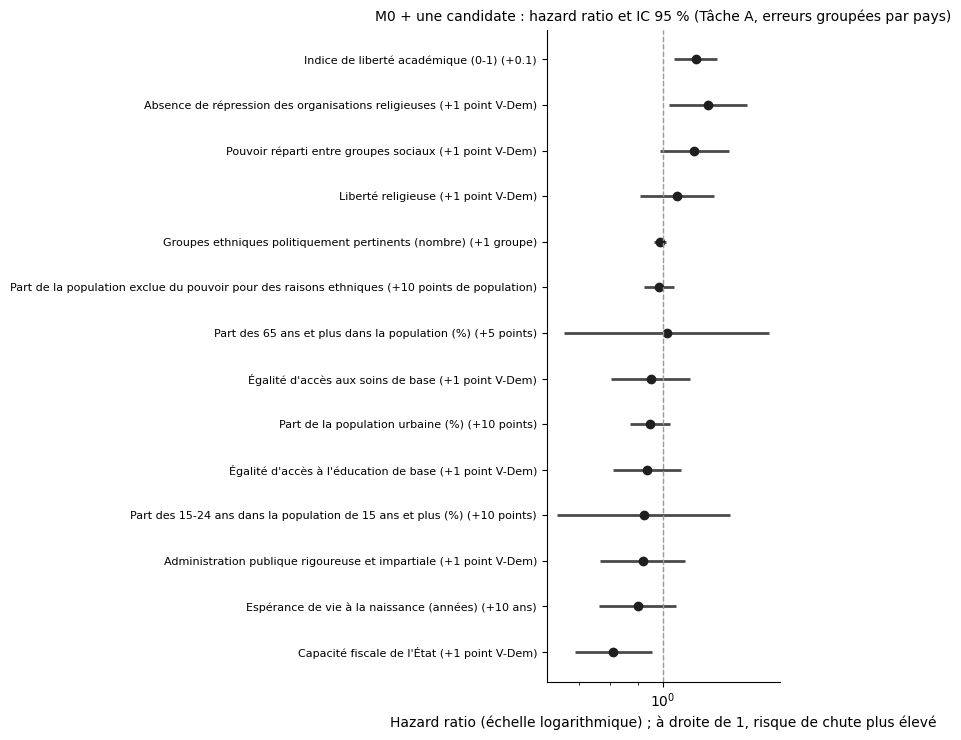

In [18]:
# ============================================================
# 6.4 Graphique : hazard ratio de chaque candidate dans son modèle combiné (Tâche A)
# ============================================================
order = combined.sort_values(["bloc", "A HR"]).index
fig, ax = plt.subplots(figsize=(8, 0.45 * len(order) + 1.2))
y = np.arange(len(order))
ax.hlines(y, combined.loc[order, "A IC bas"], combined.loc[order, "A IC haut"], color="#4a4a4a", linewidth=2)
ax.plot(combined.loc[order, "A HR"], y, "o", color="#1f1f1f", markersize=6)
ax.axvline(1, color="#9a9a9a", linestyle="--", linewidth=1)
ax.set_yticks(y, [f"{LABEL[v]} ({UNIT[v]})" for v in order], fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("Hazard ratio (échelle logarithmique) ; à droite de 1, risque de chute plus élevé")
ax.set_title("M0 + une candidate : hazard ratio et IC 95 % (Tâche A, erreurs groupées par pays)", fontsize=10)
ax.grid(axis="x", alpha=0.25)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

In [19]:
# ============================================================
# 6.5 Variables non testables : estimations descriptives (hors règles de décision)
# ============================================================
UNTESTABLE = list(dropped) + list(removed_for_sample)
REDUCED_TV = ["log_gdppc_lag1", "polity2_lag1"]          # modèle réduit de la Tâche B (Section 5)
DESC_COLS = ["bloc", "unité", "spells (A)", "chutes (A)", "parti-années (B)", "chutes (B)", "première année (B)",
             "HR (A, M0 + variable)", "IC bas (A, M0 + variable)", "IC haut (A, M0 + variable)", "p (A, M0 + variable)",
             "HR (B, réduit)", "IC bas (B, réduit)", "IC haut (B, réduit)", "p (B, réduit)"]
desc_rows = []
for v in UNTESTABLE:
    da, dt = MS.dropna(subset=SF + [v]), MT.dropna(subset=TF + [v])
    row = {"variable": v, "bloc": SPECS[v][0], "unité": UNIT[v], "spells (A)": len(da), "chutes (A)": int(da["event"].sum()),
           "parti-années (B)": len(dt), "chutes (B)": int(dt["event"].sum()),
           "première année (B)": int(dt["panel_year"].min()) if len(dt) else np.nan}
    if len(da) and epp(da, len(SF) + 1) >= MIN_EPP:
        row.update({f"{k} (A, M0 + variable)": x for k, x in hr_of(fit_static(da, SF + [v]), v).items() if k != "coef"})
    if len(dt) and epp(dt, len(REDUCED_TV) + 1) >= MIN_EPP:
        row.update({f"{k} (B, réduit)": x for k, x in hr_of(fit_tv(dt, [v] + REDUCED_TV), v).items() if k != "coef"})
    desc_rows.append(row)
descriptive = pd.DataFrame(desc_rows, columns=["variable"] + DESC_COLS).set_index("variable")
display(Markdown(
    "**Variables non testables** (couverture insuffisante pour les règles de la Section 5) — estimations descriptives : "
    f"M0 + la variable en Tâche A, et modèle time-varying réduit (variable, log du PIB par habitant, Polity2) en Tâche B, "
    f"chacun seulement s'il garde au moins {MIN_EPP} chutes par paramètre. Ces modèles portent sur des sous-échantillons "
    "plus petits, souvent plus récents : ils ne sont comparables ni à M0 ni entre eux."))
display(descriptive.round(3))

**Variables non testables** (couverture insuffisante pour les règles de la Section 5) — estimations descriptives : M0 + la variable en Tâche A, et modèle time-varying réduit (variable, log du PIB par habitant, Polity2) en Tâche B, chacun seulement s'il garde au moins 10 chutes par paramètre. Ces modèles portent sur des sous-échantillons plus petits, souvent plus récents : ils ne sont comparables ni à M0 ni entre eux.

,bloc,unité,spells (A),chutes (A),parti-années (B),chutes (B),première année (B),"HR (A, M0 + variable)","IC bas (A, M0 + variable)","IC haut (A, M0 + variable)","p (A, M0 + variable)","HR (B, réduit)","IC bas (B, réduit)","IC haut (B, réduit)","p (B, réduit)"
variable,,,,,,,,,,,,,,,
school_enrol,A,+10 points,70,58,2100,108,1971,NaN,NaN,NaN,NaN,0.967,0.889,1.052,0.429
gini,A,+10 points,15,13,1073,58,1980,NaN,NaN,NaN,NaN,0.845,0.637,1.120,0.241
unemployment,C,+5 points,76,62,1488,79,1992,NaN,NaN,NaN,NaN,0.996,0.841,1.179,0.963
youth_unemployment,C,+10 points,76,62,1488,79,1992,NaN,NaN,NaN,NaN,0.996,0.849,1.169,0.961
unemployment_advanced,C,+5 points,5,4,596,28,1971,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tertiary_enrol,C,+10 points,64,53,2165,104,1971,NaN,NaN,NaN,NaN,1.009,0.880,1.158,0.894
bachelor_share,C,+10 points,5,4,621,25,1971,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education_years,C,+1 année,162,142,2782,148,1947,0.987,0.937,1.04,0.626,0.966,0.905,1.031,0.300


## 7. Validation croisée (prédiction)

Le moteur d'évaluation reprend les fonctions de `03_ml_survival.ipynb` (Sections 3.3 et 4.3), avec une seule adaptation aux sous-échantillons : pour le score de Brier intégré, un spell de test plus long que le plus long spell du pli d'apprentissage est exclu de ce score (l'estimateur de la censure n'est pas défini au-delà) ; le nombre de spells ainsi exclus est rapporté, et la situation ne se produit jamais sur l'échantillon complet. Avant toute comparaison, il est vérifié : appliqué à M0 sur l'échantillon complet, il doit retrouver **exactement** les scores enregistrés par `03_ml_survival.ipynb` pour le modèle de Cox, pli par pli. Les 50 plis sont calculés en parallèle ; chaque calcul est déterministe.

In [20]:
# ============================================================
# 7.1 Moteur d'évaluation (Tâche A : survie par spell ; Tâche B : hasard annuel)
# ============================================================
FOLDS = pd.read_csv(PROC / "ml_folds.csv", dtype={"row_id": str})
FOLDS_A = FOLDS.query("dataset == 'static'")
FOLDS_B = FOLDS.query("dataset == 'timevarying'").astype({"row_id": int})
WEIGHTS = np.round(np.linspace(0, 1, 11), 1)


def fold_assignment(df, rep, task):
    folds = FOLDS_A if task == "A" else FOLDS_B
    key = df["spell_id"] if task == "A" else df["row_id"]
    return folds[folds["repetition"] == rep].set_index("row_id").loc[key, "fold"].values


def inner_splits(train):
    return list(StratifiedGroupKFold(n_splits=N_INNER, shuffle=True, random_state=RANDOM_STATE)
                .split(train, train["event"], train["Country"]))


def usable(train, feats):
    return [c for c in feats if train[c].var() > 0]     # une covariable constante ne peut pas être estimée


def cox_fit(train, feats):
    return CoxPHFitter(penalizer=PENALIZER).fit(train[["duration", "event"] + feats], "duration", "event")


def ctv_fit(train, feats):
    return CoxTimeVaryingFitter(penalizer=PENALIZER).fit(train[["spell_id", "start", "stop", "event"] + feats],
                                                         id_col="spell_id", start_col="start", stop_col="stop",
                                                         event_col="event")


def ctv_probability(model, train, test, feats):
    """Probabilités annuelles du Cox time-varying, hasard de base constant par classe de durée (03, 4.2)."""
    risk = model.predict_partial_hazard(train[feats]).values
    bins = train["time_bin_code"].values
    h0 = pd.Series(train["event"].values).groupby(bins).sum() / pd.Series(risk).groupby(bins).sum()
    h = h0.reindex(test["time_bin_code"].values).values
    assert not np.isnan(h).any(), "classe de durée absente du pli d'apprentissage"
    return 1 - np.exp(-h * model.predict_partial_hazard(test[feats]).values)


def blend_weight_A(train, f0, f1):
    """Poids du mélange choisi dans le pli d'apprentissage : C de Harrell moyen sur 3 plis internes."""
    score = np.zeros(len(WEIGHTS))
    for i_tr, i_va in inner_splits(train):
        tr, va = train.iloc[i_tr], train.iloc[i_va]
        lp = [cox_fit(tr, usable(tr, f)).predict_log_partial_hazard(va[usable(tr, f)]).values for f in (f0, f1)]
        for j, w in enumerate(WEIGHTS):
            score[j] += concordance_index_censored(va["event"].astype(bool), va["duration"], (1 - w) * lp[0] + w * lp[1])[0]
    return float(WEIGHTS[int(np.argmax(score))])


def blend_weight_B(train, f0, f1):
    """Poids du mélange choisi dans le pli d'apprentissage : perte logarithmique moyenne sur 3 plis internes."""
    score = np.zeros(len(WEIGHTS))
    for i_tr, i_va in inner_splits(train):
        tr, va = train.iloc[i_tr], train.iloc[i_va]
        p = [ctv_probability(ctv_fit(tr, usable(tr, f)), tr, va, usable(tr, f)) for f in (f0, f1)]
        for j, w in enumerate(WEIGHTS):
            score[j] += log_loss(va["event"], (1 - w) * p[0] + w * p[1], labels=[0, 1])
    return float(WEIGHTS[int(np.argmin(score))])


def brier_A(y_tr, y_te, surv, grid, test_time, train_max):
    """Score de Brier intégré. Si l'estimateur de la censure du pli d'apprentissage n'est pas défini pour un spell de
    test plus long que le plus long spell d'apprentissage, ce spell est exclu de ce score seulement (et la grille
    ramenée au suivi des spells restants) ; cela n'arrive jamais sur l'échantillon complet."""
    if len(grid) < 2:
        return np.nan, 0
    try:
        return integrated_brier_score(y_tr, y_te, surv, grid), 0
    except ValueError as err:
        if "largest observed time point" not in str(err):
            raise
    keep = test_time <= train_max
    on_grid = grid < test_time[keep].max()
    return integrated_brier_score(y_tr, y_te[keep], surv[keep][:, on_grid], grid[on_grid]), int((~keep).sum())


def fold_A(df, assignment, rep, k, models, blends):
    warnings.filterwarnings("ignore")
    train, test = df[assignment != k], df[assignment == k]
    y_tr = Surv.from_arrays(event=train["event"].astype(bool), time=train["duration"])
    y_te = Surv.from_arrays(event=test["event"].astype(bool), time=test["duration"])
    tau = float(np.percentile(train["duration"], 80))
    grid = np.arange(max(1, int(np.ceil(test["duration"].min()))), int(min(test["duration"].max(), train["duration"].max())))
    preds = {}
    for name, feats in models.items():
        f = usable(train, feats)
        m = cox_fit(train, f)
        preds[name] = (m.predict_log_partial_hazard(test[f]).values, m.predict_survival_function(test[f], times=grid).values.T, np.nan)
    for name, base, other in blends:
        w = blend_weight_A(train, models[base], models[other])
        preds[name] = ((1 - w) * preds[base][0] + w * preds[other][0], (1 - w) * preds[base][1] + w * preds[other][1], w)
    rows = []
    for name, (lp, surv, w) in preds.items():
        ibs, excluded = brier_A(y_tr, y_te, surv, grid, test["duration"].values, train["duration"].max())
        rows.append({"model": name, "repetition": rep, "fold": k, "n_train": len(train), "n_test": len(test),
                     "events_test": int(test["event"].sum()), "censored_test": int((test["event"] == 0).sum()),
                     "harrell_c": concordance_index_censored(y_te["event"], y_te["time"], lp)[0],
                     "uno_c": concordance_index_ipcw(y_tr, y_te, lp, tau=tau)[0],
                     "ibs": ibs, "ibs_excluded": excluded, "weight": w})
    return rows


def fold_B(df, assignment, rep, k, models, blends):
    warnings.filterwarnings("ignore")
    train, test = df[assignment != k], df[assignment == k]
    preds = {}
    for name, feats in models.items():
        f = usable(train, feats)
        preds[name] = (ctv_probability(ctv_fit(train, f), train, test, f), np.nan)
    for name, base, other in blends:
        w = blend_weight_B(train, models[base], models[other])
        preds[name] = ((1 - w) * preds[base][0] + w * preds[other][0], w)
    rows = []
    for name, (p, w) in preds.items():
        rows.append({"model": name, "repetition": rep, "fold": k, "n_train": len(train), "n_test": len(test),
                     "events_test": int(test["event"].sum()), "event_rate": float(test["event"].mean()),
                     "roc_auc": roc_auc_score(test["event"], p), "pr_auc": average_precision_score(test["event"], p),
                     "brier": brier_score_loss(test["event"], p), "log_loss": log_loss(test["event"], p, labels=[0, 1]),
                     "weight": w})
    return rows


def evaluate(task, df, models, blends=(), comparison=""):
    """Les 50 plis (5 plis x 10 répétitions) en parallèle ; une ligne par modèle et par pli."""
    df = df.reset_index(drop=True)
    assignments = {rep: fold_assignment(df, rep, task) for rep in range(N_REPEATS)}
    worker = fold_A if task == "A" else fold_B
    out = Parallel(n_jobs=-1)(delayed(worker)(df, assignments[rep], rep, k, models, blends)
                              for rep in range(N_REPEATS) for k in range(N_FOLDS))
    return pd.DataFrame([r for rows in out for r in rows]).assign(comparison=comparison)

In [21]:
# ============================================================
# 7.2 Vérification : M0 sur l'échantillon complet retrouve les scores de 03_ml_survival.ipynb
# ============================================================
start = time.perf_counter()
check_A = evaluate("A", MS, {"M0": SF})
check_B = evaluate("B", MT, {"M0": TF})
ref_A = pd.read_csv(PROC / "ml_results_taskA.csv").query("model == 'Cox'").set_index(["repetition", "fold"])
ref_B = pd.read_csv(PROC / "ml_results_taskB.csv").query("model == 'Cox time-varying'").set_index(["repetition", "fold"])
gaps = {}
for (check, ref, metrics) in [(check_A, ref_A, ["harrell_c", "uno_c", "ibs"]),
                               (check_B, ref_B, ["roc_auc", "pr_auc", "brier", "log_loss"])]:
    mine = check.set_index(["repetition", "fold"]).loc[ref.index]
    for m in metrics:
        gaps[m] = float((mine[m] - ref[m]).abs().max())
assert max(gaps.values()) < 1e-9, gaps
display(Markdown(
    f"**Vérification réussie** ({time.perf_counter() - start:.0f} s). Sur l'échantillon complet, le moteur retrouve, "
    f"pli par pli, les scores du modèle de Cox de `03_ml_survival.ipynb` (écart maximal {max(gaps.values()):.1e}) : "
    f"C de Harrell {ref_A['harrell_c'].mean():.3f}, ROC-AUC {ref_B['roc_auc'].mean():.3f} en moyenne sur 50 plis."
))

**Vérification réussie** (6 s). Sur l'échantillon complet, le moteur retrouve, pli par pli, les scores du modèle de Cox de `03_ml_survival.ipynb` (écart maximal 9.7e-17) : C de Harrell 0.616, ROC-AUC 0.673 en moyenne sur 50 plis.

In [22]:
# ============================================================
# 7.3 Comparaisons des blocs (Tâches A et B)
# ============================================================
def comparison_models(b, task):
    base = SF if task == "A" else TF
    m1, m2, m3 = MODEL_NAMES[b]
    models = {"M0": base, m1: retained[b], **{f"{m2}·{v}": base + [v] for v in retained[b]}}
    if b in CONTROL:
        cname, _, add_a, add_b = CONTROL[b]
        added = add_a if task == "A" else add_b
        if added:
            models.update({f"{cname}·{v}": base + [v] + added for v in retained[b]})
    return models, [(m3, "M0", m1)]


start = time.perf_counter()
CV = {"A": [], "B": []}
for b in ACTIVE:
    sa, tb = SAMPLES_M[b]
    for task, data in (("A", sa), ("B", tb)):
        models, blends = comparison_models(b, task)
        CV[task].append(evaluate(task, data, models, blends, comparison=f"bloc {b}"))
cv_A, cv_B = pd.concat(CV["A"], ignore_index=True), pd.concat(CV["B"], ignore_index=True)
excluded = cv_A[cv_A["model"] == "M0"].groupby("comparison")["ibs_excluded"].agg(["sum", lambda x: int((x > 0).sum())])
print(f"Validation croisée des blocs : {(time.perf_counter() - start) / 60:.1f} min "
      f"({cv_A['model'].nunique() + cv_B['model'].nunique()} modèles x 50 plis)")
print("Spells de test exclus du score de Brier intégré (total sur 50 plis ; plis concernés) :",
      {c: (int(r["sum"]), int(r["<lambda_0>"])) for c, r in excluded.iterrows()})

Validation croisée des blocs : 1.6 min (53 modèles x 50 plis)
Spells de test exclus du score de Brier intégré (total sur 50 plis ; plis concernés) : {'bloc A': (4, 2), 'bloc B': (0, 0), 'bloc C': (2, 2)}


In [23]:
# ============================================================
# 7.4 Scores moyens et tests appariés contre M0
# ============================================================
METRICS = {"A": {"harrell_c": ("C de Harrell", True), "uno_c": ("C d'Uno", True), "ibs": ("Brier intégré", False)},
           "B": {"roc_auc": ("ROC-AUC", True), "pr_auc": ("PR-AUC", True), "brier": ("Brier", False),
                 "log_loss": ("Perte log.", False)}}
PRIMARY = {"A": ("harrell_c", "ibs"), "B": ("roc_auc", "log_loss")}


def corrected_ttest(d, n_train, n_test):
    """Test t rééchantillonné corrigé (Nadeau & Bengio, 2003) pour des différences appariées."""
    J = len(d)
    t_stat = d.mean() / np.sqrt((1 / J + n_test / n_train) * d.var(ddof=1))
    return t_stat, 2 * stats.t.sf(abs(t_stat), df=J - 1)


def compare(cv, task):
    rows = []
    for comp, d in cv.groupby("comparison", sort=False):
        ref = d[d["model"] == "M0"].set_index(["repetition", "fold"])
        n_train, n_test = d["n_train"].mean(), d["n_test"].mean()
        for model in d["model"].unique():
            m = d[d["model"] == model].set_index(["repetition", "fold"])
            assert (m["n_test"] == ref["n_test"]).all(), f"{comp} / {model} : plis différents de M0"
            row = {"comparaison": comp, "modèle": model}
            for metric, (label, _) in METRICS[task].items():
                row[label] = f"{m[metric].mean():.3f} ± {m[metric].std():.3f}"
                if model != "M0":
                    diff = (m[metric] - ref[metric]).dropna()
                    _, p = corrected_ttest(diff, n_train, n_test)
                    row[f"{label} : écart"] = diff.mean()
                    row[f"{label} : p corrigée"] = p
            if model != "M0":
                disc, prob = PRIMARY[task]
                dl, pl = METRICS[task][disc][0], METRICS[task][prob][0]
                better = row[f"{dl} : p corrigée"] < ALPHA and row[f"{dl} : écart"] > 0
                worse_prob = row[f"{pl} : p corrigée"] < ALPHA and row[f"{pl} : écart"] > 0
                worse = row[f"{dl} : p corrigée"] < ALPHA and row[f"{dl} : écart"] < 0
                row["verdict"] = ("meilleur que M0" if better and not worse_prob else
                                  "moins bon que M0" if worse else "pas de différence nette")
                if not np.isnan(m["weight"]).all():
                    row["poids moyen du bloc"] = m["weight"].mean()
            else:
                row["verdict"] = "référence"
            rows.append(row)
    return pd.DataFrame(rows)


tests_A, tests_B = compare(cv_A, "A"), compare(cv_B, "B")
full_ref = {"C de Harrell": f"{ref_A['harrell_c'].mean():.3f} ± {ref_A['harrell_c'].std():.3f}",
            "ROC-AUC": f"{ref_B['roc_auc'].mean():.3f} ± {ref_B['roc_auc'].std():.3f}"}
display(Markdown(f"**Tâche A** (survie par spell ; M0 sur l'échantillon complet de `03_ml_survival.ipynb` : C de Harrell "
                 f"{full_ref['C de Harrell']}) :"))
with pd.option_context("display.max_columns", None, "display.width", 250):
    display(tests_A.round(4))
display(Markdown(f"**Tâche B** (hasard annuel ; M0 sur l'échantillon complet : ROC-AUC {full_ref['ROC-AUC']}) :"))
with pd.option_context("display.max_columns", None, "display.width", 250):
    display(tests_B.round(4))

**Tâche A** (survie par spell ; M0 sur l'échantillon complet de `03_ml_survival.ipynb` : C de Harrell 0.616 ± 0.043) :

,comparaison,modèle,C de Harrell,C d'Uno,Brier intégré,verdict,C de Harrell : écart,C de Harrell : p corrigée,C d'Uno : écart,C d'Uno : p corrigée,Brier intégré : écart,Brier intégré : p corrigée,poids moyen du bloc
0,bloc A,M0,0.621 ± 0.054,0.621 ± 0.055,0.167 ± 0.042,référence,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,bloc A,D1,0.500 ± 0.056,0.503 ± 0.057,0.189 ± 0.042,moins bon que M0,-0.1206,0.0008,-0.1178,0.0014,0.0219,0.0337,NaN
2,bloc A,D2·youth_share,0.619 ± 0.054,0.619 ± 0.054,0.167 ± 0.042,pas de différence nette,-0.0018,0.6616,-0.0019,0.6441,0.0004,0.6089,NaN
3,bloc A,D2·old_share,0.617 ± 0.054,0.617 ± 0.054,0.168 ± 0.041,pas de différence nette,-0.0040,0.3399,-0.0039,0.3602,0.0011,0.2202,NaN
4,bloc A,D2·life_exp,0.615 ± 0.049,0.613 ± 0.049,0.167 ± 0.041,pas de différence nette,-0.0065,0.4454,-0.0072,0.4377,0.0007,0.7976,NaN
5,bloc A,D2·urban_share,0.611 ± 0.050,0.610 ± 0.050,0.168 ± 0.041,pas de différence nette,-0.0101,0.1529,-0.0107,0.1591,0.0008,0.8182,NaN
6,bloc A,D2·v2stfisccap,0.634 ± 0.046,0.634 ± 0.046,0.163 ± 0.037,pas de différence nette,0.0130,0.3417,0.0138,0.3224,-0.0041,0.4128,NaN
7,bloc A,D2·v2clrspct,0.615 ± 0.050,0.614 ± 0.051,0.168 ± 0.040,pas de différence nette,-0.0065,0.3939,-0.0067,0.3881,0.0008,0.6528,NaN
8,bloc A,D2·v2peedueq,0.614 ± 0.054,0.613 ± 0.054,0.169 ± 0.041,pas de différence nette,-0.0074,0.2690,-0.0081,0.2349,0.0018,0.4492,NaN
9,bloc A,D2·v2pehealth,0.615 ± 0.051,0.614 ± 0.052,0.169 ± 0.041,pas de différence nette,-0.0062,0.3394,-0.0063,0.3474,0.0024,0.2849,NaN


**Tâche B** (hasard annuel ; M0 sur l'échantillon complet : ROC-AUC 0.673 ± 0.034) :

,comparaison,modèle,ROC-AUC,PR-AUC,Brier,Perte log.,verdict,ROC-AUC : écart,ROC-AUC : p corrigée,PR-AUC : écart,PR-AUC : p corrigée,Brier : écart,Brier : p corrigée,Perte log. : écart,Perte log. : p corrigée,poids moyen du bloc
0,bloc A,M0,0.665 ± 0.042,0.132 ± 0.037,0.049 ± 0.004,0.198 ± 0.013,référence,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,bloc A,D1,0.599 ± 0.040,0.086 ± 0.020,0.050 ± 0.004,0.204 ± 0.013,moins bon que M0,-0.0665,0.0004,-0.0465,0.0107,0.0007,0.0732,0.0062,0.0046,NaN
2,bloc A,D2·youth_share,0.664 ± 0.042,0.132 ± 0.037,0.049 ± 0.004,0.198 ± 0.013,pas de différence nette,-0.0019,0.2542,-0.0002,0.8126,0.0000,0.2014,0.0002,0.1541,NaN
3,bloc A,D2·old_share,0.669 ± 0.042,0.127 ± 0.037,0.049 ± 0.004,0.198 ± 0.013,pas de différence nette,0.0035,0.2380,-0.0047,0.5288,0.0001,0.4935,0.0001,0.8460,NaN
4,bloc A,D2·life_exp,0.664 ± 0.041,0.128 ± 0.036,0.049 ± 0.004,0.199 ± 0.013,pas de différence nette,-0.0012,0.7386,-0.0037,0.4457,0.0001,0.4228,0.0004,0.4676,NaN
5,bloc A,D2·urban_share,0.663 ± 0.042,0.131 ± 0.037,0.049 ± 0.004,0.198 ± 0.013,pas de différence nette,-0.0029,0.1467,-0.0008,0.7998,0.0000,0.2261,0.0003,0.1233,NaN
6,bloc A,D2·v2stfisccap,0.666 ± 0.047,0.137 ± 0.041,0.049 ± 0.004,0.198 ± 0.013,pas de différence nette,0.0005,0.9490,0.0053,0.5046,-0.0002,0.4167,-0.0005,0.6986,NaN
7,bloc A,D2·v2clrspct,0.664 ± 0.043,0.132 ± 0.037,0.049 ± 0.004,0.198 ± 0.013,pas de différence nette,-0.0018,0.4450,-0.0001,0.9665,0.0000,0.2324,0.0003,0.2358,NaN
8,bloc A,D2·v2peedueq,0.665 ± 0.042,0.128 ± 0.038,0.049 ± 0.004,0.199 ± 0.013,pas de différence nette,-0.0005,0.8867,-0.0038,0.5992,0.0002,0.3927,0.0006,0.3857,NaN
9,bloc A,D2·v2pehealth,0.664 ± 0.042,0.132 ± 0.037,0.049 ± 0.004,0.199 ± 0.013,pas de différence nette,-0.0019,0.3904,-0.0005,0.9100,0.0001,0.4077,0.0006,0.3199,NaN


## 8. Décision et modèle final

Application des quatre conditions de la Section 5 à chaque candidate.

In [24]:
# ============================================================
# 8.1 Décision pour chaque candidate
# ============================================================
holm_reject, holm_p, _, _ = multipletests(combined.loc[CAND, "A p"].values, alpha=ALPHA, method="holm")
decision = pd.DataFrame(index=CAND)
decision["bloc"] = [SPECS[v][0] for v in CAND]
decision["unité"] = [UNIT[v] for v in CAND]
decision["HR (A)"] = combined.loc[CAND, "A HR"]
decision["p (A)"] = combined.loc[CAND, "A p"]
decision["p Holm"] = holm_p
decision["1. Holm < 0,05"] = holm_p < ALPHA
decision["HR (B)"] = combined.loc[CAND, "B HR"]
decision["2. même sens"] = np.sign(combined.loc[CAND, "A coef"]) == np.sign(combined.loc[CAND, "B coef"])
ta = tests_A.set_index("modèle")
combined_model = {v: f"{MODEL_NAMES[SPECS[v][0]][1]}·{v}" for v in CAND}
decision["écart C (A)"] = [ta.loc[combined_model[v], "C de Harrell : écart"] for v in CAND]
decision["p corrigée C"] = [ta.loc[combined_model[v], "C de Harrell : p corrigée"] for v in CAND]
decision["3. C > M0"] = (decision["écart C (A)"] > 0) & (decision["p corrigée C"] < ALPHA)
decision["contrôle"] = [CONTROL[SPECS[v][0]][1] if SPECS[v][0] in CONTROL else "" for v in CAND]
decision["4. contrôle"] = pd.Series([bool(np.sign(combined.loc[v, "contrôle A coef"]) == np.sign(combined.loc[v, "A coef"])
                                          and combined.loc[v, "contrôle A p"] < ALPHA) if SPECS[v][0] in CONTROL else None
                                     for v in CAND], index=CAND, dtype=object)
decision["retenue"] = (decision["1. Holm < 0,05"] & decision["2. même sens"] & decision["3. C > M0"]
                       & decision["4. contrôle"].map(lambda x: True if x is None else bool(x)))
KEPT = decision.index[decision["retenue"]].tolist()
display(decision.round(4))


def reasons(v):
    d = decision.loc[v]
    out = []
    if not d["1. Holm < 0,05"]:
        out.append(f"p ajustée de Holm {d['p Holm']:.3f}")
    if not d["2. même sens"]:
        out.append("sens différent en Tâches A et B")
    if not d["3. C > M0"]:
        out.append(f"C-index {d['écart C (A)']:+.4f} par rapport à M0 (p corrigée = {d['p corrigée C']:.3f})")
    if d["4. contrôle"] is False:
        out.append("ne survit pas au contrôle " + ("régional" if SPECS[v][0] == "B" else "du PIB par habitant"))
    return out


display(Markdown(
    f"**Variables retenues** : {', '.join(f'`{v}`' for v in KEPT) if KEPT else 'aucune'}.\n\n"
    + "\n".join(f"- `{v}` ({LABEL[v]}) : " + ("retenue" if v in KEPT else "écartée — " + " ; ".join(reasons(v)))
                for v in CAND)
))

,bloc,unité,HR (A),p (A),p Holm,"1. Holm < 0,05",HR (B),2. même sens,écart C (A),p corrigée C,3. C > M0,contrôle,4. contrôle,retenue
youth_share,A,+10 points,0.9205,0.6566,1.0000,False,1.0211,False,-0.0018,0.6616,False,,None,False
old_share,A,+5 points,1.0161,0.9426,1.0000,False,1.1969,True,-0.0040,0.3399,False,,None,False
life_exp,A,+10 ans,0.8973,0.1893,1.0000,False,0.9075,True,-0.0065,0.4454,False,,None,False
urban_share,A,+10 points,0.9461,0.2030,1.0000,False,0.9820,True,-0.0101,0.1529,False,,None,False
v2stfisccap,A,+1 point V-Dem,0.8102,0.0110,0.1429,False,0.8385,True,0.0130,0.3417,False,,None,False
v2clrspct,A,+1 point V-Dem,0.9171,0.3479,1.0000,False,0.9702,True,-0.0065,0.3939,False,,None,False
v2peedueq,A,+1 point V-Dem,0.9341,0.3589,1.0000,False,0.9384,True,-0.0074,0.2690,False,,None,False
v2pehealth,A,+1 point V-Dem,0.9486,0.5358,1.0000,False,0.9711,True,-0.0062,0.3394,False,,None,False
epr_excluded,B,+10 points de population,0.9822,0.5757,1.0000,False,0.9616,True,-0.0034,0.4026,False,région,False,False
epr_groups,B,+1 groupe,0.9866,0.3160,1.0000,False,0.9806,True,-0.0025,0.5572,False,région,False,False


**Variables retenues** : aucune.

- `youth_share` (Part des 15-24 ans dans la population de 15 ans et plus (%)) : écartée — p ajustée de Holm 1.000 ; sens différent en Tâches A et B ; C-index -0.0018 par rapport à M0 (p corrigée = 0.662)
- `old_share` (Part des 65 ans et plus dans la population (%)) : écartée — p ajustée de Holm 1.000 ; C-index -0.0040 par rapport à M0 (p corrigée = 0.340)
- `life_exp` (Espérance de vie à la naissance (années)) : écartée — p ajustée de Holm 1.000 ; C-index -0.0065 par rapport à M0 (p corrigée = 0.445)
- `urban_share` (Part de la population urbaine (%)) : écartée — p ajustée de Holm 1.000 ; C-index -0.0101 par rapport à M0 (p corrigée = 0.153)
- `v2stfisccap` (Capacité fiscale de l'État) : écartée — p ajustée de Holm 0.143 ; C-index +0.0130 par rapport à M0 (p corrigée = 0.342)
- `v2clrspct` (Administration publique rigoureuse et impartiale) : écartée — p ajustée de Holm 1.000 ; C-index -0.0065 par rapport à M0 (p corrigée = 0.394)
- `v2peedueq` (Égalité d'accès à l'éducation de base) : écartée — p ajustée de Holm 1.000 ; C-index -0.0074 par rapport à M0 (p corrigée = 0.269)
- `v2pehealth` (Égalité d'accès aux soins de base) : écartée — p ajustée de Holm 1.000 ; C-index -0.0062 par rapport à M0 (p corrigée = 0.339)
- `epr_excluded` (Part de la population exclue du pouvoir pour des raisons ethniques) : écartée — p ajustée de Holm 1.000 ; C-index -0.0034 par rapport à M0 (p corrigée = 0.403) ; ne survit pas au contrôle régional
- `epr_groups` (Groupes ethniques politiquement pertinents (nombre)) : écartée — p ajustée de Holm 1.000 ; C-index -0.0025 par rapport à M0 (p corrigée = 0.557) ; ne survit pas au contrôle régional
- `v2pepwrsoc` (Pouvoir réparti entre groupes sociaux) : écartée — p ajustée de Holm 0.840 ; C-index +0.0013 par rapport à M0 (p corrigée = 0.899) ; ne survit pas au contrôle régional
- `v2clrelig` (Liberté religieuse) : écartée — p ajustée de Holm 1.000 ; C-index -0.0044 par rapport à M0 (p corrigée = 0.511) ; ne survit pas au contrôle régional
- `v2csrlgrep` (Absence de répression des organisations religieuses) : écartée — p ajustée de Holm 0.297 ; C-index +0.0122 par rapport à M0 (p corrigée = 0.332)
- `academic_freedom` (Indice de liberté académique (0-1)) : écartée — C-index +0.0165 par rapport à M0 (p corrigée = 0.350)

In [25]:
# ============================================================
# 8.2 Modèle final F (seulement si au moins une variable est retenue)
# ============================================================
final = None
if KEPT:
    sF, tF = MS.dropna(subset=SF + KEPT), MT.dropna(subset=TF + KEPT)
    epp_F = {"A": epp(sF, len(SF) + len(KEPT)), "B": epp(tF, len(TF) + len(KEPT))}
    if min(epp_F.values()) >= MIN_EPP:
        m_a, m_b = fit_static(sF, SF + KEPT), fit_tv(tF, TF + KEPT)
        MODELS_FULL[("F", "A")], MODELS_FULL[("F", "B")] = m_a, m_b
        cv_FA = evaluate("A", sF, {"M0": SF, "F": SF + KEPT}, comparison="modèle final")
        cv_FB = evaluate("B", tF, {"M0": TF, "F": TF + KEPT}, comparison="modèle final")
        cv_A, cv_B = pd.concat([cv_A, cv_FA], ignore_index=True), pd.concat([cv_B, cv_FB], ignore_index=True)
        tests_A, tests_B = compare(cv_A, "A"), compare(cv_B, "B")
        final = {"variables": KEPT, "spells": len(sF), "events": int(sF["event"].sum()), "rows_tv": len(tF),
                 "events_tv": int(tF["event"].sum()), "epp": epp_F,
                 "hazard_ratios_A": pd.DataFrame({v: hr_of(m_a, v) for v in KEPT}).T,
                 "hazard_ratios_B": pd.DataFrame({v: hr_of(m_b, v) for v in KEPT}).T}
        display(Markdown(f"**Modèle final F** : M0 + {', '.join(f'`{v}`' for v in KEPT)} ; {len(sF)} spells, "
                         f"{int(sF['event'].sum())} chutes ({epp_F['A']:.1f} chutes par paramètre)."))
        display(final["hazard_ratios_A"].round(3))
        display(tests_A[tests_A["comparaison"] == "modèle final"].round(4))
        display(tests_B[tests_B["comparaison"] == "modèle final"].round(4))
    else:
        display(Markdown(f"Le modèle final F n'est pas estimé : {min(epp_F.values()):.1f} chutes par paramètre "
                         f"(minimum {MIN_EPP})."))
else:
    display(Markdown("**Aucune variable n'est retenue** : le modèle final F n'est pas estimé, et le modèle existant reste "
                     "le modèle de référence."))

cv_A.to_csv(PROC / "demo_cv_taskA.csv", index=False)
cv_B.to_csv(PROC / "demo_cv_taskB.csv", index=False)
print(f"data/processed/demo_cv_taskA.csv ({len(cv_A)} lignes) ; data/processed/demo_cv_taskB.csv ({len(cv_B)} lignes)")

**Aucune variable n'est retenue** : le modèle final F n'est pas estimé, et le modèle existant reste le modèle de référence.

data/processed/demo_cv_taskA.csv (1450 lignes) ; data/processed/demo_cv_taskB.csv (1400 lignes)


## 9. Conclusion et limites

In [26]:
# ============================================================
# 9. Conclusion et limites (générées à partir des résultats)
# ============================================================
def fmt_p(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"


def num(x, d=2):
    return f"{x:.{d}f}"


def lc(text):
    return text[:1].lower() + text[1:]


def signed(x, d):
    return f"{'+' if x >= 0 else '−'}{num(abs(x), d)}"


def model_line(task_tests, model, disc):
    r = task_tests.set_index("modèle").loc[model]
    label = METRICS["A" if disc == "harrell_c" else "B"][disc][0]
    return r[label], r[f"{label} : écart"], r[f"{label} : p corrigée"], r["verdict"]


def link(hr, p):
    if p >= ALPHA:
        return "pas de lien net avec la durée"
    return "risque de chute plus faible" if hr < 1 else "risque de chute plus élevé"


lines = []
for b in ACTIVE:
    m1, m2, m3 = MODEL_NAMES[b]
    comp = f"bloc {b}"
    tA = tests_A[tests_A["comparaison"] == comp]
    tB = tests_B[tests_B["comparaison"] == comp]
    m0_c = tA.set_index("modèle").loc["M0", "C de Harrell"]
    c1, d1, p1, v1 = model_line(tA, m1, "harrell_c")
    c3, d3, p3, v3 = model_line(tA, m3, "harrell_c")
    auc1, da1, pa1, va1 = model_line(tB, m1, "roc_auc")
    w3 = tA.set_index("modèle").loc[m3, "poids moyen du bloc"]
    best = tA[tA["modèle"].str.startswith(f"{m2}·")].sort_values("C de Harrell : écart", ascending=False).iloc[0]
    best_v, best_d, best_p = best["modèle"].split("·")[1], best["C de Harrell : écart"], best["C de Harrell : p corrigée"]
    sa, tb = SAMPLES[b]
    lines.append(
        f"**Bloc {b} ({BLOCK_NAMES[b]})** — échantillon commun de {len(sa)} spells ({int(sa['event'].sum())} chutes) en "
        f"Tâche A et de {len(tb):,} parti-années ({int(tb['event'].sum())} chutes) en Tâche B. Sur cet échantillon, M0 "
        f"atteint un C de Harrell de {m0_c}. Seules, les variables du bloc ({m1}) obtiennent {c1} ({signed(d1, 3)} par "
        f"rapport à M0, {fmt_p(p1)} ; {v1}) en Tâche A et une ROC-AUC de {auc1} ({va1}) en Tâche B. Le mélange {m3} donne "
        f"en moyenne un poids de {num(w3, 2)} au modèle du bloc et un C de Harrell de {c3} ({v3}). "
        + (f"La seule candidate testée, `{best_v}`, change le C de Harrell de {signed(best_d, 4)} ({fmt_p(best_p)})."
           if len(retained[b]) == 1 else
           f"La candidate qui améliore le plus M0 est `{best_v}` ({signed(best_d, 4)}, {fmt_p(best_p)}).")
    )

sig_raw = decision.index[decision["p (A)"] < ALPHA].tolist()
if KEPT:
    verdict_txt = (f"Selon les règles fixées en Section 5, {len(KEPT)} variable(s) apporte(nt) une information mesurable "
                   f"au-delà du modèle existant : {', '.join(f'`{v}` ({lc(LABEL[v])})' for v in KEPT)}.")
else:
    verdict_txt = ("**Selon les règles fixées en Section 5, aucune variable démographique, de services publics, ethnique, "
                   "religieuse, d'emploi ou d'éducation n'apporte d'information mesurable au-delà du modèle existant** : "
                   "aucune ne remplit les quatre conditions.")
p_A = decision["p (A)"]
raw_txt = (f" Avant correction pour comparaisons multiples, {len(sig_raw)} candidate(s) ont p < 0.05 dans le modèle "
           f"statique combiné ({', '.join(f'`{v}` ({fmt_p(p_A[v])})' for v in sig_raw)})"
           if sig_raw else " Aucune candidate n'a p < 0.05 dans le modèle statique combiné, même avant correction")
raw_txt += f" ; la méthode de Holm porte sur {len(CAND)} candidates."


def failed_conditions(v):
    d = decision.loc[v]
    failed = [n for n, ok in ((1, d["1. Holm < 0,05"]), (2, d["2. même sens"]), (3, d["3. C > M0"])) if not ok]
    return failed + ([4] if d["4. contrôle"] is False else [])


WORDS = {2: "deux", 3: "trois", 4: "quatre"}
near = [v for v in CAND if v not in KEPT and len(failed_conditions(v)) == 1]
near_txt = ""
for v in near:
    d, c, b = decision.loc[v], combined.loc[v], SPECS[v][0]
    n_cond = 4 if b in CONTROL else 3
    control = "régional" if b == "B" else "du PIB par habitant"
    what = {1: f"son effet ne reste pas significatif après la correction de Holm (p ajustée = {d['p Holm']:.3f})",
            2: "son effet change de sens entre les Tâches A et B",
            3: (f"son ajout au modèle existant n'améliore pas nettement le C-index en validation croisée "
                f"({signed(d['écart C (A)'], 4)}, p corrigée = {d['p corrigée C']:.3f})"),
            4: f"son effet ne résiste pas au contrôle {control}"}[failed_conditions(v)[0]]
    parts = [f"hazard ratio de {num(d['HR (A)'])} pour {UNIT[v]} en Tâche A (p ajustée de Holm = {d['p Holm']:.3f})",
             f"{num(d['HR (B)'])} en Tâche B"]
    if b in CONTROL:
        parts.append(f"{num(c['contrôle A HR'])} avec le contrôle {control} ({fmt_p(c['contrôle A p'])})")
    regime = (f" ; cet indicateur décrit aussi le comportement du régime (corrélation de "
              f"{regime_corr.loc[v, 'polity2_entry']:.2f} avec le score Polity2 à l'entrée)" if v in regime_corr.index else "")
    near_txt += (f"\n\n**Presque retenue : `{v}` ({lc(LABEL[v])}).** Elle remplit {WORDS[n_cond - 1]} des "
                 f"{WORDS[n_cond]} conditions — " + ", ".join(parts) + f" — mais {what}. Plus sa valeur est élevée, plus "
                 f"le risque de chute est {'élevé' if d['HR (A)'] > 1 else 'faible'}, à valeurs égales des facteurs du "
                 "modèle existant (dont le score Polity2)" + regime + " : c'est une association, pas un effet.")

comparison_txt = ""
if "epr_excluded" in combined.index:
    e = combined.loc["epr_excluded"]
    fe, fr = frac_table.loc["al_ethnic2000"], frac_table.loc["al_religion2000"]
    ethnic_txt = (f"Pour comparaison (hors règle de décision), la part de la population exclue du pouvoir (EPR) a un hazard "
                  f"ratio de {num(e['A HR'])} pour 10 points de population ({fmt_p(e['A p'])} ; {link(e['A HR'], e['A p'])}) "
                  f"et la fractionnalisation ethnique d'Alesina et al. (2003) un hazard ratio de {num(fe['HR (A)'])} pour "
                  f"0.1 ({fmt_p(fe['p (A)'])} ; {link(fe['HR (A)'], fe['p (A)'])}).")
    if e["A p"] >= ALPHA and fe["p (A)"] >= ALPHA:
        ethnic_txt += (" Ni la mesure politique de l'exclusion ni la mesure démographique de la diversité ethnique ne sont "
                       "liées de façon nette à la durée des partis.")
    religion_txt = (f" La fractionnalisation religieuse a un hazard ratio de {num(fr['HR (A)'])} pour 0.1 en Tâche A "
                    f"({fmt_p(fr['p (A)'])}) et de {num(fr['HR (B)'])} en Tâche B ({fmt_p(fr['p (B)'])})")
    if fr["p (A)"] < ALPHA:
        religion_txt += (f" : les partis de pays plus divers sur le plan religieux ont en moyenne un "
                         f"{link(fr['HR (A)'], fr['p (A)'])}. Avec les indicateurs régionaux, le hazard ratio est de "
                         f"{num(fr['HR (A, région)'])} ({fmt_p(fr['p (A, région)'])}) : le lien "
                         + ("subsiste à l'intérieur des régions." if fr["p (A, région)"] < ALPHA
                            else "ne survit pas au contrôle régional.")
                         + " C'est une association, pas un effet")
    religion_txt += (". Ces indices ne peuvent pas être retenus : mesurés vers 2000, après le début de la plupart des "
                     "spells, ils peuvent refléter l'action des régimes eux-mêmes sur la composition de la population.")
    comparison_txt = ethnic_txt + religion_txt


def describe(v):
    r = descriptive.loc[v]
    parts = []
    if pd.notna(r["HR (A, M0 + variable)"]):
        parts.append(f"hazard ratio de {num(r['HR (A, M0 + variable)'])} pour {UNIT[v]} avec M0 en Tâche A "
                     f"({fmt_p(r['p (A, M0 + variable)'])} ; {link(r['HR (A, M0 + variable)'], r['p (A, M0 + variable)'])})")
    if pd.notna(r["HR (B, réduit)"]):
        parts.append(f"{num(r['HR (B, réduit)'])} pour {UNIT[v]} dans le modèle réduit de la Tâche B, sur les années "
                     f"{int(r['première année (B)'])} et suivantes ({fmt_p(r['p (B, réduit)'])} ; "
                     f"{link(r['HR (B, réduit)'], r['p (B, réduit)'])})")
    return f"`{v}` : " + (" ; ".join(parts) if parts else "trop peu de chutes pour un modèle")


untestable_txt = ""
if UNTESTABLE:
    untestable_txt = (
        f"**Variables non testables.** {len(UNTESTABLE)} candidates n'ont pas assez de données pour être soumises aux "
        "règles : " + "; ".join(f"`{v}` ({lc(LABEL[v])})" for v in UNTESTABLE) + ". À titre descriptif seulement "
        "(Section 6.5) : " + " ; ".join(describe(v) for v in UNTESTABLE) + ". Ces estimations portent sur des "
        "sous-échantillons plus petits, souvent plus récents, et sur des modèles plus simples que M0 : elles ne sont "
        "comparables ni à M0 ni entre elles, et ne comptent pas dans la décision.")

display(Markdown("### 9.1 Réponse\n\n" + verdict_txt + raw_txt + near_txt + "\n\n" + "\n\n".join(lines) + "\n\n" + comparison_txt
                 + ("\n\n" + untestable_txt if untestable_txt else "")))

n_static, n_ev = len(static), int(static["event"].sum())
lost_A = n_ev - int(SAMPLES["A"][0]["event"].sum()) if "A" in SAMPLES else 0
unemp = coverage.loc["unemployment"]
educ = coverage.loc["education_years"]
limits = [
    f"**Couverture avant 1960** : les séries de la Banque mondiale commencent en 1960 et celles des Nations unies en 1950 ; "
    f"l'échantillon commun du bloc A perd {lost_A} des {n_ev} chutes du modèle statique, surtout parmi les partis arrivés "
    "au pouvoir dans les années 1940 et 1950. Les blocs ne sont donc pas comparés sur le même échantillon que M0 dans "
    "`03_ml_survival.ipynb`, d'où la réestimation de M0 sur chaque échantillon.",
    f"**Chômage : des séries récentes** : les taux de chômage harmonisés (estimations modélisées du BIT) commencent en "
    f"1991 ; ils ne couvrent que {unemp['A : chutes']} chutes en Tâche A et {unemp['B : chutes']} en Tâche B. Les "
    "statistiques nationales plus anciennes ne sont pas harmonisées et existent surtout pour les démocraties. Le chômage "
    "ne peut donc pas être relié à la durée de la plupart des partis de l'ARPD, arrivés au pouvoir avant 1991.",
    f"**Éducation : des séries reconstruites** : les années moyennes d'études (Clio-Infra) sont estimées à partir "
    f"d'observations espacées, interpolées par V-Dem, et s'arrêtent en 2010 ({educ['A : chutes']} chutes en Tâche A, "
    f"{educ['B : chutes']} en Tâche B) ; la scolarisation dans le supérieur et la part de diplômés commencent en 1970 et "
    "restent rares pour les régimes autoritaires. Le nombre d'« intellectuels » n'est donc mesuré qu'indirectement.",
    "**Variables écartées** : " + ("; ".join(
        f"`{v}` ({lc(LABEL[v])} : {dropped[v] if v in dropped else removed_reason[v]})" for v in UNTESTABLE)
        + ". Elles ne peuvent pas être testées sans imputation, que le protocole exclut." if UNTESTABLE else "aucune."),
    "**Frontières actuelles** : les séries des Nations unies, de la Banque mondiale et de QoG décrivent les pays actuels ; "
    "elles ne sont pas utilisées pour l'URSS, la Yougoslavie, le Pakistan avant 1972 ni le Viêt Nam du Nord, mais le sont "
    "pour des changements territoriaux plus limités (Éthiopie avant 1993, Soudan avant 2011).",
    "**Fractionnalisation mesurée après les spells** : les indices d'Alesina et al. (2003) datent d'environ 2000 ; ils "
    "peuvent refléter l'action des régimes eux-mêmes (exodes, expulsions, violences de masse). C'est pourquoi ils ne "
    "servent que de comparaison.",
    "**Colinéarité** : les variables de développement (espérance de vie, urbanisation, structure par âge, éducation) sont "
    "fortement corrélées entre elles et avec le PIB par habitant (Section 4.4) ; leurs effets propres sont difficiles à "
    "séparer, ce qui justifie de les tester une à une et, pour le bloc C, de contrôler le PIB.",
    "**Indicateurs qui décrivent aussi le régime** : la liberté religieuse, la répression des organisations religieuses, "
    "la répartition du pouvoir entre groupes sociaux et la liberté académique sont en partie des choix du régime ; un lien "
    "avec sa durée ne dit pas si la société ou le régime en est à l'origine.",
    f"**Peu d'événements** : les modèles combinés restent juste au-dessus de {MIN_EPP} chutes par paramètre ; un effet "
    "modeste peut passer inaperçu, et l'absence de gain prédictif ne prouve pas l'absence de tout lien.",
    "**Erreurs standards du modèle time-varying** : non groupées par pays, comme dans `final_panel.ipynb` ; la condition 2 "
    "n'utilise que le sens de l'effet en Tâche B, pas sa significativité.",
]
display(Markdown("### 9.2 Limites\n\n" + "\n".join(f"* {l}" for l in limits)))

recommendation = ("**Recommandation pour le site.** Aucune variable n'étant retenue, le modèle de la simulation ne change "
                  "pas. Ce résultat est présenté dans la page Analyse comme un test de robustesse : les caractéristiques "
                  "des pays testées ici n'ajoutent pas d'information mesurable aux facteurs propres aux partis."
                  if not KEPT else
                  f"**Recommandation pour le site.** Les variables retenues ({', '.join(KEPT)}) décrivent des pays, pas des "
                  "choix d'un parti : elles ne doivent pas devenir des paramètres de la simulation. Si le modèle du site "
                  "devait les intégrer, ce serait comme contexte fixé par le pays choisi, après réexamen du modèle exporté "
                  "(`src/cox_static_model.json`) et de ses tests.")
display(Markdown(recommendation))

### 9.1 Réponse

**Selon les règles fixées en Section 5, aucune variable démographique, de services publics, ethnique, religieuse, d'emploi ou d'éducation n'apporte d'information mesurable au-delà du modèle existant** : aucune ne remplit les quatre conditions. Avant correction pour comparaisons multiples, 3 candidate(s) ont p < 0.05 dans le modèle statique combiné (`v2stfisccap` (p = 0.011), `v2csrlgrep` (p = 0.025), `academic_freedom` (p = 0.003)) ; la méthode de Holm porte sur 14 candidates.

**Presque retenue : `academic_freedom` (indice de liberté académique (0-1)).** Elle remplit trois des quatre conditions — hazard ratio de 1.15 pour +0.1 en Tâche A (p ajustée de Holm = 0.041), 1.12 en Tâche B, 1.15 avec le contrôle du PIB par habitant (p = 0.002) — mais son ajout au modèle existant n'améliore pas nettement le C-index en validation croisée (+0.0165, p corrigée = 0.350). Plus sa valeur est élevée, plus le risque de chute est élevé, à valeurs égales des facteurs du modèle existant (dont le score Polity2) ; cet indicateur décrit aussi le comportement du régime (corrélation de 0.57 avec le score Polity2 à l'entrée) : c'est une association, pas un effet.

**Bloc A (démographie et services publics)** — échantillon commun de 172 spells (148 chutes) en Tâche A et de 3,056 parti-années (161 chutes) en Tâche B. Sur cet échantillon, M0 atteint un C de Harrell de 0.621 ± 0.054. Seules, les variables du bloc (D1) obtiennent 0.500 ± 0.056 (−0.121 par rapport à M0, p < 0.001 ; moins bon que M0) en Tâche A et une ROC-AUC de 0.599 ± 0.040 (moins bon que M0) en Tâche B. Le mélange D3 donne en moyenne un poids de 0.20 au modèle du bloc et un C de Harrell de 0.615 ± 0.052 (pas de différence nette). La candidate qui améliore le plus M0 est `v2stfisccap` (+0.0130, p = 0.342).

**Bloc B (ethnicité et religion)** — échantillon commun de 220 spells (192 chutes) en Tâche A et de 3,648 parti-années (193 chutes) en Tâche B. Sur cet échantillon, M0 atteint un C de Harrell de 0.610 ± 0.041. Seules, les variables du bloc (E1) obtiennent 0.588 ± 0.041 (−0.022 par rapport à M0, p = 0.408 ; pas de différence nette) en Tâche A et une ROC-AUC de 0.631 ± 0.046 (moins bon que M0) en Tâche B. Le mélange E3 donne en moyenne un poids de 0.43 au modèle du bloc et un C de Harrell de 0.615 ± 0.037 (pas de différence nette). La candidate qui améliore le plus M0 est `v2csrlgrep` (+0.0122, p = 0.332).

**Bloc C (emploi, éducation et liberté académique)** — échantillon commun de 180 spells (158 chutes) en Tâche A et de 3,542 parti-années (183 chutes) en Tâche B. Sur cet échantillon, M0 atteint un C de Harrell de 0.597 ± 0.059. Seules, les variables du bloc (S1) obtiennent 0.614 ± 0.047 (+0.017 par rapport à M0, p = 0.622 ; pas de différence nette) en Tâche A et une ROC-AUC de 0.643 ± 0.041 (pas de différence nette) en Tâche B. Le mélange S3 donne en moyenne un poids de 0.78 au modèle du bloc et un C de Harrell de 0.614 ± 0.057 (pas de différence nette). La seule candidate testée, `academic_freedom`, change le C de Harrell de +0.0165 (p = 0.350).

Pour comparaison (hors règle de décision), la part de la population exclue du pouvoir (EPR) a un hazard ratio de 0.98 pour 10 points de population (p = 0.576 ; pas de lien net avec la durée) et la fractionnalisation ethnique d'Alesina et al. (2003) un hazard ratio de 0.99 pour 0.1 (p = 0.606 ; pas de lien net avec la durée). Ni la mesure politique de l'exclusion ni la mesure démographique de la diversité ethnique ne sont liées de façon nette à la durée des partis. La fractionnalisation religieuse a un hazard ratio de 0.92 pour 0.1 en Tâche A (p = 0.004) et de 0.93 en Tâche B (p = 0.009) : les partis de pays plus divers sur le plan religieux ont en moyenne un risque de chute plus faible. Avec les indicateurs régionaux, le hazard ratio est de 0.92 (p = 0.005) : le lien subsiste à l'intérieur des régions. C'est une association, pas un effet. Ces indices ne peuvent pas être retenus : mesurés vers 2000, après le début de la plupart des spells, ils peuvent refléter l'action des régimes eux-mêmes sur la composition de la population.

**Variables non testables.** 8 candidates n'ont pas assez de données pour être soumises aux règles : `school_enrol` (taux brut de scolarisation dans le secondaire (%)); `gini` (indice de Gini des revenus (0-100)); `unemployment` (taux de chômage (% de la population active)); `youth_unemployment` (taux de chômage des 15-24 ans (%)); `unemployment_advanced` (taux de chômage des diplômés du supérieur (%)); `tertiary_enrol` (taux brut de scolarisation dans le supérieur (%)); `bachelor_share` (part des 25 ans et plus titulaires d'une licence (%)); `education_years` (années moyennes d'études des 15 ans et plus). À titre descriptif seulement (Section 6.5) : `school_enrol` : 0.97 pour +10 points dans le modèle réduit de la Tâche B, sur les années 1971 et suivantes (p = 0.429 ; pas de lien net avec la durée) ; `gini` : 0.84 pour +10 points dans le modèle réduit de la Tâche B, sur les années 1980 et suivantes (p = 0.241 ; pas de lien net avec la durée) ; `unemployment` : 1.00 pour +5 points dans le modèle réduit de la Tâche B, sur les années 1992 et suivantes (p = 0.963 ; pas de lien net avec la durée) ; `youth_unemployment` : 1.00 pour +10 points dans le modèle réduit de la Tâche B, sur les années 1992 et suivantes (p = 0.961 ; pas de lien net avec la durée) ; `unemployment_advanced` : trop peu de chutes pour un modèle ; `tertiary_enrol` : 1.01 pour +10 points dans le modèle réduit de la Tâche B, sur les années 1971 et suivantes (p = 0.894 ; pas de lien net avec la durée) ; `bachelor_share` : trop peu de chutes pour un modèle ; `education_years` : hazard ratio de 0.99 pour +1 année avec M0 en Tâche A (p = 0.626 ; pas de lien net avec la durée) ; 0.97 pour +1 année dans le modèle réduit de la Tâche B, sur les années 1947 et suivantes (p = 0.300 ; pas de lien net avec la durée). Ces estimations portent sur des sous-échantillons plus petits, souvent plus récents, et sur des modèles plus simples que M0 : elles ne sont comparables ni à M0 ni entre elles, et ne comptent pas dans la décision.

### 9.2 Limites

* **Couverture avant 1960** : les séries de la Banque mondiale commencent en 1960 et celles des Nations unies en 1950 ; l'échantillon commun du bloc A perd 47 des 195 chutes du modèle statique, surtout parmi les partis arrivés au pouvoir dans les années 1940 et 1950. Les blocs ne sont donc pas comparés sur le même échantillon que M0 dans `03_ml_survival.ipynb`, d'où la réestimation de M0 sur chaque échantillon.
* **Chômage : des séries récentes** : les taux de chômage harmonisés (estimations modélisées du BIT) commencent en 1991 ; ils ne couvrent que 62 chutes en Tâche A et 79 en Tâche B. Les statistiques nationales plus anciennes ne sont pas harmonisées et existent surtout pour les démocraties. Le chômage ne peut donc pas être relié à la durée de la plupart des partis de l'ARPD, arrivés au pouvoir avant 1991.
* **Éducation : des séries reconstruites** : les années moyennes d'études (Clio-Infra) sont estimées à partir d'observations espacées, interpolées par V-Dem, et s'arrêtent en 2010 (142 chutes en Tâche A, 148 en Tâche B) ; la scolarisation dans le supérieur et la part de diplômés commencent en 1970 et restent rares pour les régimes autoritaires. Le nombre d'« intellectuels » n'est donc mesuré qu'indirectement.
* **Variables écartées** : `school_enrol` (taux brut de scolarisation dans le secondaire (%) : 58 chutes en Tâche A, 108 en Tâche B); `gini` (indice de Gini des revenus (0-100) : 13 chutes en Tâche A, 58 en Tâche B); `unemployment` (taux de chômage (% de la population active) : 62 chutes en Tâche A, 79 en Tâche B); `youth_unemployment` (taux de chômage des 15-24 ans (%) : 62 chutes en Tâche A, 79 en Tâche B); `unemployment_advanced` (taux de chômage des diplômés du supérieur (%) : 4 chutes en Tâche A, 28 en Tâche B); `tertiary_enrol` (taux brut de scolarisation dans le supérieur (%) : 53 chutes en Tâche A, 104 en Tâche B); `bachelor_share` (part des 25 ans et plus titulaires d'une licence (%) : 4 chutes en Tâche A, 25 en Tâche B); `education_years` (années moyennes d'études des 15 ans et plus : échantillon commun du bloc : 124 chutes en Tâche A et 144 en Tâche B, soit 8.9 et 10.3 chutes par paramètre pour le plus grand modèle prévu). Elles ne peuvent pas être testées sans imputation, que le protocole exclut.
* **Frontières actuelles** : les séries des Nations unies, de la Banque mondiale et de QoG décrivent les pays actuels ; elles ne sont pas utilisées pour l'URSS, la Yougoslavie, le Pakistan avant 1972 ni le Viêt Nam du Nord, mais le sont pour des changements territoriaux plus limités (Éthiopie avant 1993, Soudan avant 2011).
* **Fractionnalisation mesurée après les spells** : les indices d'Alesina et al. (2003) datent d'environ 2000 ; ils peuvent refléter l'action des régimes eux-mêmes (exodes, expulsions, violences de masse). C'est pourquoi ils ne servent que de comparaison.
* **Colinéarité** : les variables de développement (espérance de vie, urbanisation, structure par âge, éducation) sont fortement corrélées entre elles et avec le PIB par habitant (Section 4.4) ; leurs effets propres sont difficiles à séparer, ce qui justifie de les tester une à une et, pour le bloc C, de contrôler le PIB.
* **Indicateurs qui décrivent aussi le régime** : la liberté religieuse, la répression des organisations religieuses, la répartition du pouvoir entre groupes sociaux et la liberté académique sont en partie des choix du régime ; un lien avec sa durée ne dit pas si la société ou le régime en est à l'origine.
* **Peu d'événements** : les modèles combinés restent juste au-dessus de 10 chutes par paramètre ; un effet modeste peut passer inaperçu, et l'absence de gain prédictif ne prouve pas l'absence de tout lien.
* **Erreurs standards du modèle time-varying** : non groupées par pays, comme dans `final_panel.ipynb` ; la condition 2 n'utilise que le sens de l'effet en Tâche B, pas sa significativité.

**Recommandation pour le site.** Aucune variable n'étant retenue, le modèle de la simulation ne change pas. Ce résultat est présenté dans la page Analyse comme un test de robustesse : les caractéristiques des pays testées ici n'ajoutent pas d'information mesurable aux facteurs propres aux partis.

## 10. Export des résultats

Les résultats sont écrits dans `data/processed/site_results_demo.json`, avec la même structure que les autres exports (tableaux au format « split » de pandas). Le site les lit (page Analyse, section « Caractéristiques des pays ») ; ses textes en français, en anglais et en arabe sont construits à partir de ces chiffres par `src/site_text.py` (`demo_texts`), comme pour les autres notebooks.

In [27]:
# ============================================================
# 10. Export (data/processed/site_results_demo.json)
# ============================================================
def metric_summary(cv, task):
    out = []
    for (comp, model), d in cv.groupby(["comparison", "model"], sort=False):
        row = {"comparison": comp, "model": model}
        for metric in METRICS[task]:
            row[metric] = {"mean": float(d[metric].mean()), "sd": float(d[metric].std())}
        out.append(row)
    return out


def sample_info(sa, tb):
    ids = sorted(sa["spell_id"])
    return {"spells": len(sa), "events": int(sa["event"].sum()), "countries": int(sa["Country"].nunique()),
            "rows_tv": len(tb), "spells_tv": int(tb["spell_id"].nunique()), "events_tv": int(tb["event"].sum()),
            "spell_ids_sha1": hashlib.sha1("|".join(ids).encode("utf-8")).hexdigest()}


site_demo = {
    "source": "notebooks/04_demographics.ipynb",
    "created": date.today().isoformat(),
    "protocol": {"folds": N_FOLDS, "repeats": N_REPEATS, "evaluations": N_FOLDS * N_REPEATS, "grouped_by": "Country",
                 "folds_file": "data/processed/ml_folds.csv", "inner_folds": N_INNER, "blend_weights": list(WEIGHTS),
                 "min_falls": MIN_FALLS, "min_events_per_parameter": MIN_EPP, "alpha": ALPHA, "multiple_testing": "holm",
                 "test": "test t rééchantillonné corrigé (Nadeau & Bengio, 2003)", "region_reference": REGION_REF,
                 "reduced_tv_model": REDUCED_TV},
    "sources": [{"file": name, **info} for name, info in log.items()]
               + [{"file": "V-Dem-CY-Full+Others-v16.csv", "version": "v16", "variables": VDEM_A + VDEM_B + VDEM_C},
                  {"file": "worldbank.csv", "series": "SI.POV.GINI"}],
    "wdi_lastupdated": wdi_updated,
    "blocks": {b: {"name": BLOCK_NAMES[b], "models": list(MODEL_NAMES[b]), "retained": retained[b],
                   "control": ({"model": CONTROL[b][0], "label": CONTROL[b][1]} if b in CONTROL else None)}
               for b in BLOCKS},
    "totals": {"spells": len(static), "events": int(static["event"].sum()), "rows_tv": len(tv),
               "events_tv": int(tv["event"].sum())},
    "candidates": candidates_table,
    "coverage": coverage.reset_index(),
    "coverage_by_decade": by_decade.reset_index(),
    "screening": {"dropped": dropped, "removed_for_sample": removed_for_sample, "removed_reason": removed_reason,
                  "retained": retained},
    "samples": {b: sample_info(sa, tb) for b, (sa, tb) in SAMPLES.items()},
    "correlations": {b: t.reset_index() for b, t in corr_tables.items()},
    "vif": {b: t.rename("VIF").reset_index() for b, t in vif_tables.items()},
    "regime_correlations": regime_corr.reset_index(),
    "events_per_parameter": epp_planned,
    "gw_cow_differences": GW_COW_DIFFERENCES,
    "models": {
        "combined": combined.reset_index(),
        "proportional_hazards": ph_table.reset_index(),
        "early_late": early_late,
        "blocks": block_models,
        "fractionalization": frac_table.reset_index(),
        "descriptive": descriptive.reset_index(),
    },
    "cv": {"task_a": {"metrics": metric_summary(cv_A, "A"), "tests": tests_A},
           "task_b": {"metrics": metric_summary(cv_B, "B"), "tests": tests_B},
           "full_sample_m0": {"harrell_c": {"mean": float(ref_A["harrell_c"].mean()), "sd": float(ref_A["harrell_c"].std())},
                              "roc_auc": {"mean": float(ref_B["roc_auc"].mean()), "sd": float(ref_B["roc_auc"].std())}}},
    "decision": decision.reset_index().rename(columns={"index": "variable"}),
    "kept": KEPT,
    "final_model": final,
}
site_demo["texts"] = demo_texts(site_demo)      # textes du site en français, anglais et arabe (src/site_text.py)
size_kb = write_json(PROC / "site_results_demo.json", site_demo)
print(f"data/processed/site_results_demo.json : {size_kb:.0f} Ko")

data/processed/site_results_demo.json : 119 Ko


## 11. Références

**Données.**
- **Alesina, A., Devleeschauwer, A., Easterly, W., Kurlat, S., & Wacziarg, R.** (2003). Fractionalization. *Journal of Economic Growth*, 8(2), 155–194. https://doi.org/10.1023/A:1024471506938
- **Clio-Infra** (2018). Clio-Infra Project (Database), *Average Years of Education*. http://www.clio-infra.eu/ (série `e_peaveduc` du fichier V-Dem Full+Others)
- **Coppedge, M., Gerring, J., et al.** (2026). V-Dem Country-Year Dataset v16. Varieties of Democracy (V-Dem) Project. https://doi.org/10.23696/vdemds26
- **International Labour Organization** (2026). *ILO modelled estimates*, ILOSTAT, diffusées par la Banque mondiale (`SL.UEM.TOTL.ZS`, `SL.UEM.1524.ZS`).
- **Spannagel, J., & Kinzelbach, K.** (2022). The Academic Freedom Index and its indicators: Introduction to new global time-series V-Dem data. *Quality & Quantity*.
- **Teorell, J., Sundström, A., Holmberg, S., Rothstein, B., Alvarado Pachon, N., Saidi Phiri, V., Chen, C., & Liu, Z.** (2026). *The Quality of Government Standard Dataset*, version Jan26. University of Gothenburg: The Quality of Government Institute. https://doi.org/10.18157/qogstdjan26
- **United Nations, Department of Economic and Social Affairs, Population Division** (2024). *World Population Prospects 2024*. https://population.un.org/wpp/
- **Vogt, M., Bormann, N.-C., Rüegger, S., Cederman, L.-E., Hunziker, P., & Girardin, L.** (2015). Integrating Data on Ethnicity, Geography, and Conflict: The Ethnic Power Relations Data Set Family. *Journal of Conflict Resolution*, 59(7), 1327–1342. https://doi.org/10.1177/0022002715591215
- **World Bank** (2026). *World Development Indicators*. https://data.worldbank.org/

**Méthodes et concepts.**
- **Campante, F. R., & Chor, D.** (2012). Why Was the Arab World Poised for Revolution? Schooling, Economic Opportunities, and the Arab Spring. *Journal of Economic Perspectives*, 26(2), 167–188. https://doi.org/10.1257/jep.26.2.167
- **Cederman, L.-E., Wimmer, A., & Min, B.** (2010). Why Do Ethnic Groups Rebel? New Data and Analysis. *World Politics*, 62(1), 87–119. https://doi.org/10.1017/S0043887109990219
- **Glaeser, E. L., Ponzetto, G. A. M., & Shleifer, A.** (2007). Why Does Democracy Need Education? *Journal of Economic Growth*, 12(2), 77–99. https://doi.org/10.1007/s10887-007-9015-1
- **Gleditsch, K. S., & Ward, M. D.** (1999). Interstate System Membership: A Revised List of the Independent States since 1816. *International Interactions*, 25(4), 393–413. https://doi.org/10.1080/03050629908434958
- **Holm, S.** (1979). A Simple Sequentially Rejective Multiple Test Procedure. *Scandinavian Journal of Statistics*, 6(2), 65–70.
- **Nadeau, C., & Bengio, Y.** (2003). Inference for the Generalization Error. *Machine Learning*, 52(3), 239–281. https://doi.org/10.1023/A:1024068626366
- **Peduzzi, P., Concato, J., Feinstein, A. R., & Holford, T. R.** (1995). Importance of events per independent variable in proportional hazards regression analysis II. *Journal of Clinical Epidemiology*, 48(12), 1503–1510. https://doi.org/10.1016/0895-4356(95)00048-8
- **Urdal, H.** (2006). A Clash of Generations? Youth Bulges and Political Violence. *International Studies Quarterly*, 50(3), 607–629. https://doi.org/10.1111/j.1468-2478.2006.00416.x